# Metro Latent Mode Discovery — Hierarchical Poisson HMM

### Scientific goal

> *How many distinct operational modes exist in the metro system and do all stations enter each mode at the same time, or does a **temporal wave** propagate across the network?*

We model the metro as a **Hidden Markov Model (HMM)** with four latent states: Night, Off-peak, Morning-rush and Evening-rush

Each state emits passenger counts (`ins`, `outs`) from a **Poisson distribution** with station and mode specific rates. A bounded per-station timing offset δ[s, k] captures how many hours earlier or later station *s* enters mode *k* relative to the system-wide canonical centre.

Training uses **Stochastic Variational Inference (SVI)** via Pyro, processing random mini-batches of days.


## Configuration

The following libraries are required: Pytorch, Pyro, pandas, matplotlib / scipy, folium.

**Key choices explained:**
- `RESAMPLE_FREQ = "15min"` —> 96 timesteps/day, fine enough to resolve rush-hour onset.
- `NUM_STATES = 4` —> Night / Off-peak / Morning-rush / Evening-rush.
- `MAX_DELAY_HOURS = 3.0` —> station offsets bounded to ±3 h via `tanh`, preventing unrealistic shifts.
- `SIGMA_HOURS` —> controls how tightly each mode is concentrated around its canonical hour.
- `TIME_DAY_INFL` —> weight of time-of-day score relative to Poisson likelihood.


In [24]:
from __future__ import annotations

from pathlib import Path
from typing import Dict, List, Tuple, Optional
import os
import re

import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import torch
import torch.nn.functional as F
import pyro
import pyro.distributions as dist
from pyro.infer import SVI, Trace_ELBO
from pyro.optim import ClippedAdam
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.ndimage import uniform_filter1d
from IPython.display import IFrame
import base64


torch.manual_seed(42)
pyro.set_rng_seed(42)

_N_THREADS = min(6, max(1, os.cpu_count() or 1))
torch.set_num_threads(_N_THREADS)
print(f"PyTorch using {_N_THREADS} CPU threads.")

%matplotlib inline
plt.rcParams["figure.dpi"] = 120

HERE = Path(".")
DATA_PATH = HERE / "metro_combined.csv"
OUT_DIR = HERE / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUT_DIR / "metro_hmm_checkpoint.pt"

RESAMPLE_FREQ = "15min"
DATE_START = "2024-04-01"
DATE_END = "2025-10-01"
STEPS_PER_DAY = 96
BATCH_DAYS = 20

NUM_STATES = 4
STATE_NAMES = ["Night", "Off-peak", "Morning-rush", "Evening-rush"]
MODE_CENTER_HOURS = torch.tensor([2.0, 12.0, 7.5, 17.0])
SIGMA_HOURS = torch.tensor([2.0, 2.5, 1.0, 1.2])
MAX_DELAY_HOURS = 3.0
DELAY_PRIOR = 1.0
TIME_DAY_INFL = 0.6

STATE_COLORS = ["#1a1a2e", "#27ae60", "#e74c3c", "#f39c12"]
STATE_COLORS_PLOT = ["#3d5a80", "#27ae60", "#e74c3c", "#f39c12"]
BG = "#0d1117"
PANEL = "#161b22"
GRID = "#21262d"
MUTED = "#8b949e"
WHITE = "#e6edf3"

print("Configuration loaded.")
print(f"  States  : {STATE_NAMES}")
print(f"  Centers : {MODE_CENTER_HOURS.tolist()} h")
print(f"  Max δ   : ±{MAX_DELAY_HOURS} h  |  TIME_DAY_INFL = {TIME_DAY_INFL}")


PyTorch using 6 CPU threads.
Configuration loaded.
  States  : ['Night', 'Off-peak', 'Morning-rush', 'Evening-rush']
  Centers : [2.0, 12.0, 7.5, 17.0] h
  Max δ   : ±3.0 h  |  TIME_DAY_INFL = 0.6


## Data loading and preprocessing

`load_data` reads the CSV, applies date filtering, cleans count columns, parses geographic coordinates, and returns:

1. **`ins` / `outs`** — `[S, T]` float32 tensors, scaled by the dataset mean for numerical stability.
2. **`ins_3d` / `outs_3d`** — `[S, D, 96]` reshaped for daily mini-batch training.
3. **`meta`** — DataFrame with station name, latitude, and longitude.

Each row represents a station at a given minute, with passenger counts and timestamp information.

### Scaling
Observations are divided by `obs_scale = max(mean(ins), mean(outs))`. All reported rates are rescaled back to passengers / 15 min.


In [2]:
def _parse_location(loc):
    """Parse WKT 'POINT (lon lat)', tuple, or 'lat,lon' into (lat, lon)."""
    if pd.isna(loc):
        return np.nan, np.nan
    loc = str(loc).strip()
    wkt = re.match(r"POINT\s*\(\s*([\d.\-]+)\s+([\d.\-]+)\s*\)", loc, re.IGNORECASE)
    if wkt:
        return float(wkt.group(2)), float(wkt.group(1))
    nums = re.findall(r"[\d.\-]+", loc)
    if len(nums) >= 2:
        return float(nums[0]), float(nums[1])
    return np.nan, np.nan


def load_data(
        path=DATA_PATH, resample_freq=RESAMPLE_FREQ,
        date_start=DATE_START, date_end=DATE_END,
        device=torch.device("cpu"),
):
    """Load, clean, resample and tensorise metro passenger data."""
    print(f"Date filter: {date_start} → {date_end}")
    df = pd.read_csv(
        path,
        usecols=["timestamp", "stationId", "stationName", "ins", "outs", "passengerNo", "location"],
        low_memory=False,
    )
    print(f"Loaded shape: {df.shape}")

    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
    if date_start: df = df[df["timestamp"] >= pd.Timestamp(date_start, tz="UTC")]
    if date_end:   df = df[df["timestamp"] < pd.Timestamp(date_end, tz="UTC")]

    for col in ("ins", "outs", "passengerNo"):
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).clip(lower=0)

    coords = df[["stationId", "stationName", "location"]].drop_duplicates("stationId").copy()
    coords[["lat", "lon"]] = coords["location"].apply(lambda x: pd.Series(_parse_location(x)))
    meta = (coords[["stationId", "stationName", "lat", "lon"]]
            .set_index("stationId").sort_index()
            .rename(columns={"stationName": "station"}))
    station_ids = meta.index.tolist()
    station_names = meta["station"].tolist()

    df = df.groupby(["stationId", "timestamp"], as_index=False)[["ins", "outs"]].sum()
    print(f"Resampling to {resample_freq} ...")
    df = (df.set_index("timestamp")
          .groupby("stationId")[["ins", "outs"]]
          .resample(resample_freq).sum().reset_index())
    print(f"After resample: {df.shape[0]:,} rows")

    time_index = pd.date_range(start=df["timestamp"].min(), end=df["timestamp"].max(), freq=resample_freq)
    S, T = len(station_ids), len(time_index)
    print(f"Stations: {S}   Timesteps: {T}   ({time_index[0]} → {time_index[-1]})")
    print(f"Memory for γ [S={S}, T={T}, K={NUM_STATES}]: {S * T * NUM_STATES * 4 / 1e6:.1f} MB")

    df_indexed = df.set_index(["stationId", "timestamp"])

    def _wide(col):
        return (df_indexed[col].unstack("timestamp")
                .reindex(index=station_ids, columns=time_index, fill_value=0)
                .fillna(0).round().astype(np.float32))

    ins_raw = torch.tensor(_wide("ins").values, dtype=torch.float32, device=device)
    outs_raw = torch.tensor(_wide("outs").values, dtype=torch.float32, device=device)

    obs_scale = max(float(ins_raw.mean()), float(outs_raw.mean()), 1.0)
    print(f"Observation scale: {obs_scale:.3f}")

    ins = ins_raw / obs_scale
    outs = outs_raw / obs_scale

    if T % STEPS_PER_DAY:
        T_trim = (T // STEPS_PER_DAY) * STEPS_PER_DAY
        ins, outs, time_index = ins[:, :T_trim], outs[:, :T_trim], time_index[:T_trim]
        T = T_trim

    D = T // STEPS_PER_DAY
    ins_3d = ins.reshape(S, D, STEPS_PER_DAY)
    outs_3d = outs.reshape(S, D, STEPS_PER_DAY)
    print(f"Daily mini-batch view: [S={S}, D={D}, T_day={STEPS_PER_DAY}]")
    return ins, outs, ins_3d, outs_3d, station_names, time_index, meta, obs_scale, D


In [3]:
device = torch.device("cpu")

ins, outs, ins_3d, outs_3d, station_names, time_index, meta, obs_scale, D = (
    load_data(DATA_PATH, device=device)
)

print(f"\n--- Data summary ---")
print(f"Stations       : {len(station_names)}")
print(f"Days           : {D}")
print(f"Date range     : {time_index[0].date()} → {time_index[-1].date()}")
print(f"ins  mean/max  : {ins.mean():.4f} / {ins.max():.2f}  (scaled)")
print(f"outs mean/max  : {outs.mean():.4f} / {outs.max():.2f}  (scaled)")
print(f"\nStation list:")
for name in station_names:
    print(f"  {name}")


Date filter: 2024-04-01 → 2025-10-01
Loaded shape: (47763600, 7)
Resampling to 15min ...
After resample: 2,275,312 rows
Stations: 44   Timesteps: 52608   (2024-04-01 00:00:00+00:00 → 2025-09-30 23:45:00+00:00)
Memory for γ [S=44, T=52608, K=4]: 37.0 MB
Observation scale: 86.147
Daily mini-batch view: [S=44, D=548, T_day=96]

--- Data summary ---
Stations       : 44
Days           : 548
Date range     : 2024-04-01 → 2025-09-30
ins  mean/max  : 0.9688 / 35.11  (scaled)
outs mean/max  : 1.0000 / 49.90  (scaled)

Station list:
  Vanløse
  Flintholm
  Lindevang
  Fasanvej
  Frederiksberg
  Forum
  Nørreport
  Kongens Nytorv
  Christianshavn
  Islands Brygge
  DR Byen
  Sundby
  Bella Center
  Ørestad
  Vestamager
  Amagerbro
  Lergravsparken
  Øresund
  Amager Strand
  Femøren
  Kastrup
  Københavns Lufthavn
  København H
  Rådhuspladsen
  Gammel Strand
  Marmorkirken
  Østerport
  Trianglen
  Poul Henningsens Plads
  Vibenshus Runddel
  Skjolds Plads
  Nørrebro
  Nørrebros Runddel
  Nuuks 

## HMM definition and emissions
A Hidden Markov Model (HMM) is defined to capture passenger-count time series.  The goal is to discover latent operating modes of the metro system that are not directly observed in the data.  The model treats the passenger count features as observations and tries to explain them via an unobserved (latent) state sequence. For each station and specific timestep, the HMM gives P(state = k | data) which captures the uncertainty: These probabilities are later averaged per station to understand which modes a station typically operates in.

### Forward algorithm

$$\alpha_t(k) = \left[\sum_{j} \alpha_{t-1}(j) \cdot A_{jk}\right] \cdot B_k(o_t)$$

### Backward algorithm

$$\beta_t(k) = \sum_{j} A_{kj} \cdot B_j(o_{t+1}) \cdot \beta_{t+1}(j)$$

### Posterior state probabilities (γ)

$$\gamma_t(k) = P(z_t = k \mid o_{1:T}) \propto \alpha_t(k) \cdot \beta_t(k)$$

All operations are in **log-space** for numerical stability. The three functions below are JIT-compiled with `@torch.jit.script`.

### Poisson emission log-PMF

$$\log P(x \mid \lambda) = x \ln \lambda - \lambda - \ln \Gamma(x+1)$$

### Station timing offsets

Each station $s$ has a mode-specific timing offset $\delta_{s,k}$, bounded to $[-3, +3]$ h via `tanh`:

$$\delta_{s,k} = 3 \cdot \tanh(\tilde{\delta}_{s,k})$$

The time-of-day score for station $s$, mode $k$, at timestep $t$:

$$\text{score}(s, t, k) = -\frac{1}{2}\left(\frac{h_t - (c_k + \delta_{s,k})}{\sigma_k}\right)^2$$

where $h_t$ is the fractional hour of day, $c_k$ the canonical centre, and $\sigma_k$ the mode width.


In [4]:
@torch.jit.script
def _hmm_forward(
        log_emit_t: torch.Tensor,  # [T, N, K]
        log_A: torch.Tensor,  # [K, K]
        log_init: torch.Tensor,  # [K]
) -> torch.Tensor:
    """Log-space forward pass. Returns log α [T, N, K]."""
    T = log_emit_t.shape[0]
    log_alphas = torch.empty_like(log_emit_t)
    log_alphas[0] = log_init.unsqueeze(0) + log_emit_t[0]
    for t in range(1, T):
        log_alphas[t] = (
                                log_alphas[t - 1].unsqueeze(2) + log_A.unsqueeze(0)
                        ).logsumexp(1) + log_emit_t[t]
    return log_alphas


@torch.jit.script
def _hmm_backward(
        log_emit_t: torch.Tensor,  # [T, N, K]
        log_A: torch.Tensor,  # [K, K]
) -> torch.Tensor:
    """Log-space backward pass. Returns log β [T, N, K]."""
    T = log_emit_t.shape[0]
    log_betas = torch.zeros_like(log_emit_t)
    for t in range(T - 2, -1, -1):
        log_betas[t] = (
                log_betas[t + 1].unsqueeze(1)
                + log_A.unsqueeze(0)
                + log_emit_t[t + 1].unsqueeze(1)
        ).logsumexp(2)
    return log_betas


@torch.jit.script
def _hmm_log_marginal(
        log_emit: torch.Tensor,
        log_A: torch.Tensor,
        log_init: torch.Tensor,
) -> torch.Tensor:
    """Log P(observations) via the forward algorithm."""
    log_emit_t = log_emit.permute(1, 0, 2)
    return _hmm_forward(log_emit_t, log_A, log_init)[-1].logsumexp(-1)


# Quick shape smoke-test with random tensors
_K, _T, _N = 4, 10, 3
_dummy_emit = torch.randn(_N, _T, _K)
_dummy_A = torch.log_softmax(torch.randn(_K, _K), dim=-1)
_dummy_init = torch.log_softmax(torch.randn(_K), dim=-1)
_lm = _hmm_log_marginal(_dummy_emit, _dummy_A, _dummy_init)
print(f"HMM functions compiled. log-marginal shape: {tuple(_lm.shape)}  (expected [{_N}])")


HMM functions compiled. log-marginal shape: (3,)  (expected [3])


In [5]:
def _poisson_log_prob(x: torch.Tensor, rate: torch.Tensor) -> torch.Tensor:
    """Numerically stable Poisson log-PMF."""
    rate = rate.clamp_min(1e-6)
    return torch.xlogy(x, rate) - rate - (x + 1.0).lgamma()


def _circular_hour_diff(hour: torch.Tensor, center: torch.Tensor) -> torch.Tensor:
    """Shortest signed distance on a 24-hour clock circle."""
    return ((hour - center + 12.0) % 24.0) - 12.0


def _bounded_delay(delay: torch.Tensor) -> torch.Tensor:
    """Map raw unconstrained offset to ±MAX_DELAY_HOURS via tanh."""
    return MAX_DELAY_HOURS * torch.tanh(delay)


def _bounded_delay_scale(raw_loc: torch.Tensor, raw_scale: torch.Tensor) -> torch.Tensor:
    """Delta-method uncertainty propagation through the tanh transform."""
    return (MAX_DELAY_HOURS * (1.0 - torch.tanh(raw_loc).pow(2))).abs() * raw_scale


def _station_timeOfDay_log_score(
        hours: torch.Tensor,  # [T]
        station_delay: torch.Tensor,  # [S, K]
) -> torch.Tensor:
    """Gaussian log-score [S, T, K] for how well each timestep fits each mode."""
    device = station_delay.device;
    K = station_delay.shape[1]
    _bc = torch.tensor([2.0, 12.0, 7.5, 17.0]);
    _bs = torch.tensor([2.0, 2.5, 1.0, 1.2])
    if K <= len(_bc):
        centers, sigmas = _bc[:K].to(device), _bs[:K].to(device)
    else:
        n_extra = K - len(_bc)
        centers = torch.cat([_bc, torch.linspace(9.0, 20.0, n_extra)]).to(device)
        sigmas = torch.cat([_bs, torch.full((n_extra,), 2.0)]).to(device)

    effective_center = centers.unsqueeze(0) + station_delay  # [S, K]
    diff = _circular_hour_diff(
        hours.unsqueeze(0).unsqueeze(-1),  # [1, T, 1]
        effective_center.unsqueeze(1),  # [S, 1, K]
    )
    return -0.5 * (diff / sigmas.unsqueeze(0).unsqueeze(0)) ** 2  # [S, T, K]


# Verify Poisson log-prob on a simple case: P(X=0 | λ=1) = e^-1 ≈ 0.368
x_test = torch.tensor(0.0)
lam_test = torch.tensor(1.0)
expected = -1.0  # log(e^-1)
result = _poisson_log_prob(x_test, lam_test).item()
print(f"Poisson log-PMF check:  log P(0|λ=1) = {result:.4f}  (expected {expected:.4f})")
print("Emission and timing-score functions defined.")


Poisson log-PMF check:  log P(0|λ=1) = -1.0000  (expected -1.0000)
Emission and timing-score functions defined.


## Mean-field approximation variational guide

### Model

Defines the generative process. The HMM is treated as a **daily model**: each day is an independent sequence of 96 timesteps sharing global parameters. Priors:

- Transition matrix: Gaussian → softmax
- Emission rates λ: Gamma, with a stronger shrinkage prior on Night
- Station delays δ: Normal(0, `DELAY_PRIOR`) on the raw (pre-tanh) scale

### Guide (variational family)

A **mean-field** approximation — each latent variable gets its own independent Gaussian (Delta for point-estimated rates). Emission rates use **empirical Bayes** initialisation: each station starts at a multiple of its own observed mean.


In [7]:
def model(ins_b: torch.Tensor, outs_b: torch.Tensor, n_states: int = NUM_STATES):
    """Hierarchical Poisson HMM — daily mini-batch version."""
    S, B, T_day = ins_b.shape;
    device = ins_b.device

    log_A_params = pyro.sample("log_A",
                               dist.Normal(torch.zeros(n_states, n_states, device=device),
                                           torch.ones(n_states, n_states, device=device)).to_event(2))
    log_A = F.log_softmax(log_A_params, dim=-1)

    init_logits = pyro.sample("init_logits",
                              dist.Normal(torch.zeros(n_states, device=device),
                                          torch.ones(n_states, device=device)).to_event(1))
    log_init = F.log_softmax(init_logits, dim=-1)

    prior_alpha = torch.full((n_states, S), 3.0, device=device)
    prior_beta = torch.full((n_states, S), 3.0, device=device)
    prior_alpha[0, :] = 1.5;
    prior_beta[0, :] = 7.5  # Night: stronger shrinkage

    with pyro.plate("state_plate", n_states, dim=-2):
        with pyro.plate("station_plate_emit", S, dim=-1):
            lambda_in = pyro.sample("lambda_in", dist.Gamma(prior_alpha, prior_beta))
            lambda_out = pyro.sample("lambda_out", dist.Gamma(prior_alpha, prior_beta))

    raw_station_delay = pyro.sample("raw_station_delay",
                                    dist.Normal(torch.zeros(S, n_states, device=device),
                                                torch.full((S, n_states), DELAY_PRIOR, device=device)).to_event(2))
    station_delay = _bounded_delay(raw_station_delay)

    ins = ins_b.reshape(S * B, T_day);
    outs = outs_b.reshape(S * B, T_day)
    lam_in_exp = lambda_in.T.repeat_interleave(B, dim=0)
    lam_out_exp = lambda_out.T.repeat_interleave(B, dim=0)

    log_emit_poisson = (
            _poisson_log_prob(ins.unsqueeze(-1), lam_in_exp.unsqueeze(1))
            + _poisson_log_prob(outs.unsqueeze(-1), lam_out_exp.unsqueeze(1))
    )
    hours_day = torch.arange(T_day, dtype=torch.float32, device=device) / 4.0
    log_emit = log_emit_poisson + TIME_DAY_INFL * _station_timeOfDay_log_score(
        hours_day, station_delay).repeat_interleave(B, dim=0)

    pyro.factor("hmm_obs", _hmm_log_marginal(log_emit, log_A, log_init).mean())


def guide(ins_b: torch.Tensor, outs_b: torch.Tensor, n_states: int = NUM_STATES):
    """Mean-field variational guide with empirical-Bayes emission initialisation."""
    S = ins_b.shape[0];
    device = ins_b.device

    log_A_init = torch.zeros(n_states, n_states, device=device) + 4.0 * torch.eye(n_states, device=device)
    log_A_mu = pyro.param("log_A_mu", log_A_init)
    pyro.sample("log_A",
                dist.Normal(log_A_mu, F.softplus(pyro.param("log_A_scale_raw",
                                                            torch.full((n_states, n_states), -2.3,
                                                                       device=device))) + 1e-4).to_event(2))

    _dl = torch.tensor([1.0, 0.2, -0.2, -0.2], dtype=torch.float32, device=device)
    init_vals = (_dl[:n_states] if n_states <= len(_dl)
                 else torch.cat([_dl, torch.zeros(n_states - len(_dl), device=device)]))
    init_logits_loc = pyro.param("init_logits_mu", init_vals)
    pyro.sample("init_logits",
                dist.Normal(init_logits_loc, F.softplus(pyro.param("init_logits_scale_raw",
                                                                   torch.full((n_states,), -2.0,
                                                                              device=device))) + 1e-4).to_event(1))

    station_mean_in = ins_b.mean(dim=(1, 2)).clamp_min(0.05)
    station_mean_out = outs_b.mean(dim=(1, 2)).clamp_min(0.05)
    _dm = torch.tensor([0.20, 0.80, 2.00, 1.60], device=device)
    mult_vals = (_dm[:n_states] if n_states <= len(_dm)
                 else torch.cat([_dm, torch.ones(n_states - len(_dm), device=device)]))

    def _inv_softplus(x):
        x = x.clamp_min(1e-4)
        return torch.where(x > 20.0, x, torch.log(torch.expm1(x)))

    init_in = (mult_vals.unsqueeze(1) * station_mean_in.unsqueeze(0)).clamp_min(0.02)
    init_out = (mult_vals.unsqueeze(1) * station_mean_out.unsqueeze(0)).clamp_min(0.02)
    lambda_in_q = F.softplus(pyro.param("lambda_in_raw", _inv_softplus(init_in.clone()))).clamp(1e-4, 50.0)
    lambda_out_q = F.softplus(pyro.param("lambda_out_raw", _inv_softplus(init_out.clone()))).clamp(1e-4, 50.0)

    with pyro.plate("state_plate", n_states, dim=-2):
        with pyro.plate("station_plate_emit", S, dim=-1):
            pyro.sample("lambda_in", dist.Delta(lambda_in_q))
            pyro.sample("lambda_out", dist.Delta(lambda_out_q))

    raw_delay = pyro.param("raw_station_delay_mu", torch.zeros(S, n_states, device=device))
    raw_scale = F.softplus(pyro.param("raw_station_delay_scale",
                                      torch.full((S, n_states), -1.2, device=device))) + 1e-3
    pyro.sample("raw_station_delay", dist.Normal(raw_delay, raw_scale).to_event(2))


print("Pyro model and guide defined.")


Pyro model and guide defined.


## SVI Training
Model parameters are learned with stochastic variational inference (SVI), which can be viewed as a stochastic, approximate generalisation of EM: instead of full E/M steps on the whole dataset, we maximise an ELBO (equivalent of minimizing the negative ELBO loss) using mini‑batch updates and an approximate posterior over latent states.

Minimises the **ELBO loss**:

$$\mathcal{L}_{\text{ELBO}} = \mathbb{E}_{q(z)}[\log p(x,z)] - \mathbb{E}_{q(z)}[\log q(z)]$$

Key choices:
- **ClippedAdam** with `clip_norm=0.5` — prevents explosive gradients in log-sum-exp.
- **LR decay** (`lrd=0.9995`) — gradual step-size reduction for stable convergence.
- **Daily mini-batching** — each step samples `BATCH_DAYS` random days.


In [8]:
def train(
        ins_3d, outs_3d, D,
        n_states=NUM_STATES, n_steps=600, batch_days=BATCH_DAYS,
        lr=0.002, clip_norm=0.5, smoothing=50,
) -> List[float]:
    """Run SVI and return the per-step ELBO loss history."""
    from tqdm.auto import tqdm
    pyro.clear_param_store()
    svi = SVI(model, guide,
              ClippedAdam({"lr": lr, "lrd": 0.9995, "clip_norm": clip_norm}),
              loss=Trace_ELBO())
    losses: List[float] = [];
    prev_smooth = None
    bar = tqdm(range(n_steps), desc="SVI training", unit="step", colour="blue")
    for _ in bar:
        B = min(batch_days, D)
        idx = torch.randperm(D, device=ins_3d.device)[:B]
        loss = float(svi.step(ins_3d[:, idx, :], outs_3d[:, idx, :], n_states))
        losses.append(loss)
        window = losses[-smoothing:];
        smooth = sum(window) / len(window)
        delta = 0.0 if prev_smooth is None else smooth - prev_smooth
        prev_smooth = smooth
        bar.set_postfix(ELBO=f"{smooth:,.0f}", Δ=f"{delta:+,.0f}", refresh=False)
    return losses


SVI training:   0%|          | 0/600 [00:00<?, ?step/s]

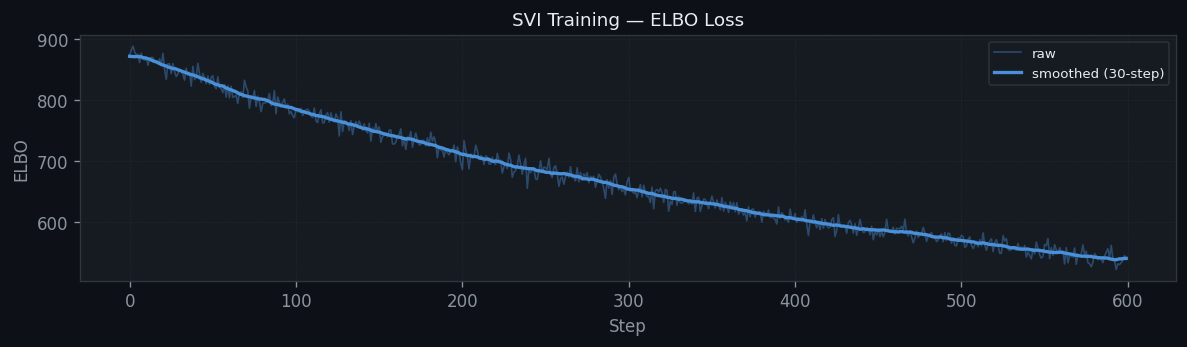

Final ELBO: 538.1


In [9]:
# ── Run training (or load checkpoint if available) ───────────────────────────
FORCE_RETRAIN = True  # set False to load from checkpoint instead

_ckpt = None
if not FORCE_RETRAIN and CHECKPOINT_PATH.exists():
    print(f"Loading checkpoint from {CHECKPOINT_PATH} ...")
    _ckpt = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    pyro.clear_param_store()
    for k, v in _ckpt["param_store"].items():
        pyro.get_param_store()[k] = v.clone()
    losses = _ckpt["losses"]
    obs_scale = _ckpt["obs_scale"]
    print(f"Loaded {len(losses)} training steps.")
else:
    losses = train(ins_3d, outs_3d, D)

# Plot ELBO loss curve
fig, ax = plt.subplots(figsize=(10, 3))
fig.patch.set_facecolor(BG);
ax.set_facecolor(PANEL)
ax.plot(losses, color="#4a90d9", lw=1.0, alpha=0.4, label="raw")
from scipy.ndimage import uniform_filter1d as _uf1

ax.plot(_uf1(losses, size=30), color="#4a90d9", lw=2.0, label="smoothed (30-step)")
ax.set_title("SVI Training — ELBO Loss", color=WHITE, fontsize=11)
ax.set_xlabel("Step", color=MUTED)
ax.set_ylabel("ELBO", color=MUTED)
ax.tick_params(colors=MUTED)
ax.grid(color=GRID, lw=0.4, ls="--")
for sp in ax.spines.values(): sp.set_color("#30363d")
ax.legend(fontsize=8, labelcolor=WHITE, facecolor=PANEL, edgecolor="#30363d")
plt.tight_layout()
plt.show()
print(f"Final ELBO: {losses[-1]:,.1f}")


## Posterior extraction

`posterior_params` reads the Pyro param store and applies softmax / softplus / tanh to recover:
- **A** — transition matrix
- **λ_in / λ_out** — Poisson rates in passengers / 15 min
- **station_delay ± scale** — timing offsets in hours with posterior uncertainty

`compute_posterior_probs` runs the full forward–backward pass over the entire observation sequence to produce the smoothed posterior $\gamma[S, T, K]$.
To interpret the numeric states, learned mean passenger levels and empirical time-of-day profiles are examined.

States with very low mean counts and high occurrence during late-night hours naturally correspond to **Night**, while high-intensity states concentrated around 7–9 and 16–18
are identified as **Morning-rush** and **Evening-rush**, respectively. Intermediate states with moderate intensities correspond to **Off-peak**.

In [10]:
@torch.no_grad()
def posterior_params(obs_scale: float = 1.0):
    """Extract and transform all learned variational parameters."""
    log_A = F.log_softmax(pyro.param("log_A_mu").detach(), dim=-1)
    A = log_A.exp()
    log_init = F.log_softmax(pyro.param("init_logits_mu").detach(), dim=-1)

    lam_in_sc = F.softplus(pyro.param("lambda_in_raw").detach()).clamp(1e-4, 50.0)
    lam_out_sc = F.softplus(pyro.param("lambda_out_raw").detach()).clamp(1e-4, 50.0)

    raw_delay = pyro.param("raw_station_delay_mu").detach()
    raw_delay_scale = F.softplus(pyro.param("raw_station_delay_scale").detach()) + 1e-3
    station_delay = _bounded_delay(raw_delay)
    station_delay_scale = _bounded_delay_scale(raw_delay, raw_delay_scale)

    return (log_A, A, log_init,
            lam_in_sc, lam_out_sc,
            lam_in_sc * obs_scale, lam_out_sc * obs_scale,
            station_delay, station_delay_scale)


@torch.no_grad()
def compute_posterior_probs(ins, outs, time_index, obs_scale):
    """Forward–backward pass → γ[S, T, K] smoothed posteriors."""
    log_A, A, log_init, lam_in_sc, lam_out_sc, lambda_in, lambda_out, station_delay, station_delay_scale = (
        posterior_params(obs_scale))

    log_emit_poisson = (
            _poisson_log_prob(ins.unsqueeze(-1), lam_in_sc.T.unsqueeze(1))
            + _poisson_log_prob(outs.unsqueeze(-1), lam_out_sc.T.unsqueeze(1))
    )
    hours = torch.tensor(
        time_index.hour.values + time_index.minute.values / 60.0,
        dtype=torch.float32, device=ins.device)
    log_emit = log_emit_poisson + TIME_DAY_INFL * _station_timeOfDay_log_score(hours, station_delay)

    log_emit_t = log_emit.permute(1, 0, 2)
    log_alphas = _hmm_forward(log_emit_t, log_A, log_init)
    log_betas = _hmm_backward(log_emit_t, log_A)

    log_gamma = log_alphas.permute(1, 0, 2) + log_betas.permute(1, 0, 2)
    log_gamma -= log_gamma.logsumexp(2, keepdim=True)
    gamma = log_gamma.exp()  # [S, T, K]

    return gamma, lambda_in, lambda_out, A, log_init.exp(), station_delay, station_delay_scale


In [11]:
print("Running forward–backward posterior smoothing ...")
gamma, lambda_in, lambda_out, A, init_probs, station_delay, station_delay_scale = (
    compute_posterior_probs(ins, outs, time_index, obs_scale)
)

S, T, K = gamma.shape
print(f"γ shape: {gamma.shape}  (stations × timesteps × states)")

# ── Poisson rates table ───────────────────────────────────────────────────────
print(f"\nPosterior Poisson rates (mean across {S} stations, pass/15-min):")
print(f"  {'Mode':<14} {'λ_in':>12} {'λ_out':>12}")
print("  " + "-" * 42)
for k, name in enumerate(STATE_NAMES):
    print(f"  {name:<14} {lambda_in[k].mean().item():>12.2f} {lambda_out[k].mean().item():>12.2f}")

# ── Transition matrix ─────────────────────────────────────────────────────────
print("\nPosterior transition matrix A[from → to]:")
print("              " + "".join(f"{n:>14}" for n in STATE_NAMES))
for i, name in enumerate(STATE_NAMES):
    print(f"  {name:<12}" + "".join(f"{A[i, j].item():>14.3f}" for j in range(K)))

# ── Initial distribution ──────────────────────────────────────────────────────
print("\nLearned initial distribution:")
for name, p in zip(STATE_NAMES, init_probs):
    print(f"  {name:<14} {p.item():.3f}")


Running forward–backward posterior smoothing ...
γ shape: torch.Size([44, 52608, 4])  (stations × timesteps × states)

Posterior Poisson rates (mean across 44 stations, pass/15-min):
  Mode                   λ_in        λ_out
  ------------------------------------------
  Night                  9.33         9.81
  Off-peak              71.03        71.46
  Morning-rush         120.52       124.41
  Evening-rush         100.08       103.77

Posterior transition matrix A[from → to]:
                       Night      Off-peak  Morning-rush  Evening-rush
  Night                0.914         0.029         0.033         0.024
  Off-peak             0.026         0.905         0.026         0.042
  Morning-rush         0.035         0.063         0.868         0.035
  Evening-rush         0.044         0.031         0.027         0.898

Learned initial distribution:
  Night          0.419
  Off-peak       0.194
  Morning-rush   0.191
  Evening-rush   0.196


In [13]:
def _hour_to_hhmm(hour: float) -> str:
    mins = int(round((hour % 24.0) * 60)) % (24 * 60)
    return f"{mins // 60:02d}:{mins % 60:02d}"


def export_station_delays(station_names, station_delay, station_delay_scale, out_path):
    """Save per-station timing offsets and onset clock times to CSV."""
    delay = station_delay.cpu().numpy();
    scale = station_delay_scale.cpu().numpy()
    rows = []
    for s, station in enumerate(station_names):
        row = {"station": station}
        for k, mode in enumerate(STATE_NAMES):
            lo = delay[s, k] - 1.96 * scale[s, k]
            hi = delay[s, k] + 1.96 * scale[s, k]
            row[f"{mode}_delay_h"] = delay[s, k]
            row[f"{mode}_delay_sd_h"] = scale[s, k]
            row[f"{mode}_delay_lo95_h"] = lo
            row[f"{mode}_delay_hi95_h"] = hi
            row[f"{mode}_relative_center"] = _hour_to_hhmm(float(MODE_CENTER_HOURS[k]) + delay[s, k])
            row[f"{mode}_relative_center_lo95"] = _hour_to_hhmm(float(MODE_CENTER_HOURS[k]) + lo)
            row[f"{mode}_relative_center_hi95"] = _hour_to_hhmm(float(MODE_CENTER_HOURS[k]) + hi)
        rows.append(row)
    df = pd.DataFrame(rows)
    df.to_csv(out_path, index=False)
    return df


def export_posterior_states(gamma, station_names, time_index, out_path):
    """Save γ[S, T, K] as long-format CSV with hard-assigned state column."""
    S, T, K = gamma.shape;
    g_np = gamma.cpu().numpy()
    data = {"station": np.repeat(station_names, T), "timestamp": np.tile(time_index, S)}
    for k, name in enumerate(STATE_NAMES):
        data[f"p_{name.replace('-', '_')}"] = g_np[:, :, k].ravel()
    data["hard_state"] = np.array(STATE_NAMES)[g_np.argmax(axis=2).ravel()]
    pd.DataFrame(data).to_csv(out_path, index=False)


def save_checkpoint(losses, obs_scale, station_names, time_index,
                    gamma, lambda_in, lambda_out, A, init_probs,
                    station_delay, station_delay_scale, meta, path):
    """Save complete training result to a .pt file."""
    param_store_dict = {k: v.detach().cpu() for k, v in pyro.get_param_store().items()}
    torch.save(dict(param_store=param_store_dict, losses=losses, obs_scale=obs_scale,
                    station_names=station_names, time_index=time_index,
                    gamma=gamma.cpu(), lambda_in=lambda_in.cpu(), lambda_out=lambda_out.cpu(),
                    A=A.cpu(), init_probs=init_probs.cpu(),
                    station_delay=station_delay.cpu(), station_delay_scale=station_delay_scale.cpu(),
                    meta=meta), path)
    print(f"Checkpoint → {path}  ({path.stat().st_size / 1e6:.1f} MB)")


In [30]:
# Export full posterior state probabilities
export_posterior_states(gamma, station_names, time_index,
                        OUT_DIR / "metro_posterior_states.csv")
print("Posterior states exported.")

# Save checkpoint
save_checkpoint(
    losses, obs_scale, station_names, time_index,
    gamma, lambda_in, lambda_out, A, init_probs,
    station_delay, station_delay_scale, meta,
    CHECKPOINT_PATH,
)


Posterior states exported.
Checkpoint → outputs\metro_hmm_checkpoint.pt  (37.6 MB)


In [34]:
# Export station timing offsets
delay_df = export_station_delays(
    station_names, station_delay, station_delay_scale,
    OUT_DIR / "metro_station_mode_delays.csv",
)
print("Station delays exported. Morning-rush onset ranking:")
print(
    delay_df[["station", "Morning-rush_delay_h", "Morning-rush_relative_center"]]
    .sort_values("Morning-rush_delay_h")
    .to_string(index=False)
)


Station delays exported. Morning-rush onset ranking:
               station  Morning-rush_delay_h Morning-rush_relative_center
               Øresund             -0.192080                        07:18
         København Syd             -0.147224                        07:21
                Sundby             -0.141634                        07:22
         Amager Strand             -0.137283                        07:22
               Femøren             -0.098341                        07:24
              Fasanvej             -0.091229                        07:25
        Lergravsparken             -0.086696                        07:25
           Sluseholmen             -0.082841                        07:25
               Kastrup             -0.080269                        07:25
            Vestamager             -0.075330                        07:25
               DR Byen             -0.072861                        07:26
          Bella Center             -0.067167               

## Visualization

Auxialiary shared dark-theme plotting functions are defined.


In [16]:
def _to_np(t) -> np.ndarray:
    return t.detach().cpu().numpy() if isinstance(t, torch.Tensor) else np.asarray(t)


def _hour_label(h: float) -> str:
    h = float(h) % 24.0;
    m = int(round(h * 60)) % (24 * 60)
    return f"{m // 60:02d}:{m % 60:02d}"


def _dark(ax, bg=PANEL):
    ax.set_facecolor(bg)
    for sp in ax.spines.values(): sp.set_color("#30363d")
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.xaxis.label.set_color(MUTED);
    ax.yaxis.label.set_color(MUTED)
    ax.title.set_color(WHITE)
    ax.grid(color=GRID, linewidth=0.4, linestyle="--", zorder=0)


def _dark_plain(ax):
    ax.set_facecolor("#161b22")
    for sp in ax.spines.values(): sp.set_color("#333")
    ax.tick_params(colors="#aaa", labelsize=7)


def _fig(figsize):
    fig = plt.figure(figsize=figsize);
    fig.patch.set_facecolor(BG);
    return fig


def _xticks_hours(ax, step=2):
    hours = list(range(0, 25, step))
    ax.set_xticks(hours)
    ax.set_xticklabels([_hour_label(h) for h in hours], fontsize=7, rotation=30, ha="right")


def _raster_time_ticks(ax, time_index, T, n_ticks=12):
    pos = np.linspace(0, T - 1, n_ticks, dtype=int)
    ax.set_xticks(pos)
    ax.set_xticklabels([time_index[i].strftime("%b %d\n%H:%M") for i in pos], color="#aaa", fontsize=6)


def _daily_gamma(gamma):
    """Average γ over calendar days → [S, STEPS_PER_DAY, K]."""
    g = _to_np(gamma);
    S, T, K = g.shape;
    D = T // STEPS_PER_DAY
    return g[:, :D * STEPS_PER_DAY, :].reshape(S, D, STEPS_PER_DAY, K).mean(axis=1)


print("Plotting utilities ready.")


Plotting utilities ready.


### Overview figure

Six-panel sanity check: ELBO curve, Poisson rates, transition matrix, state raster, timing offset bars, and soft posteriors for one station.


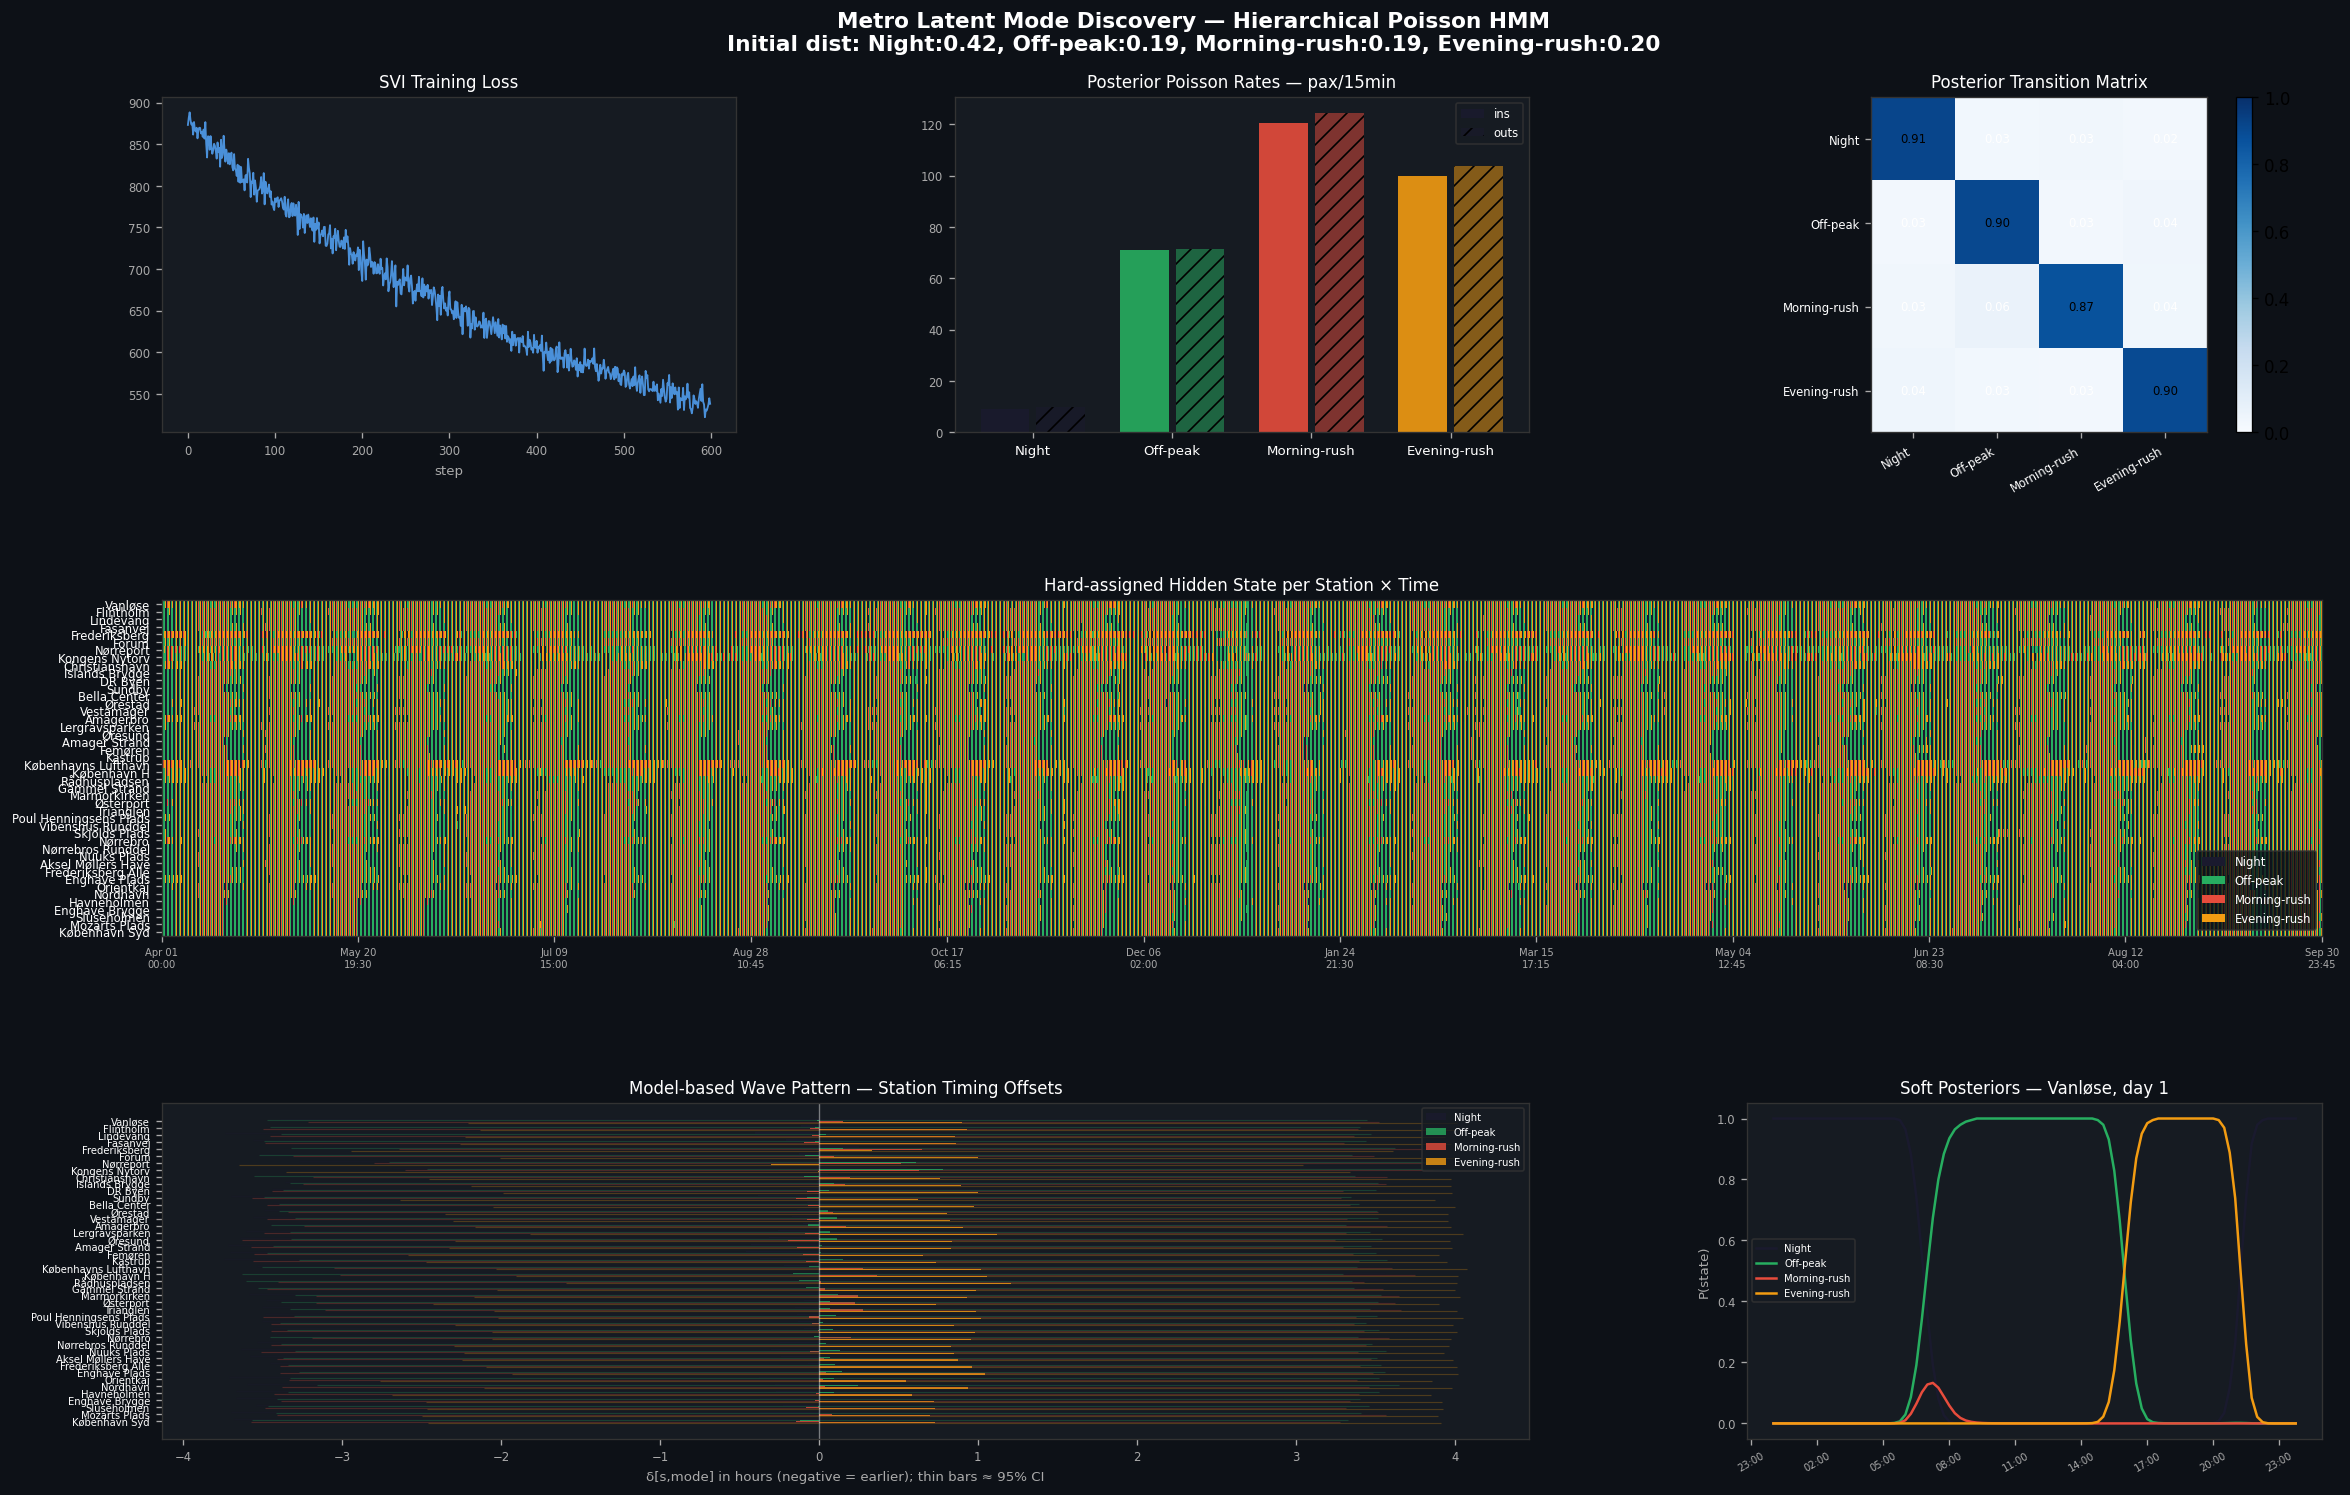

Saved → outputs\plots\metro_hmm_results.png


In [17]:
S_plot, T_plot, K_plot = gamma.shape
bg = "#161b22"

fig = plt.figure(figsize=(20, 13));
fig.patch.set_facecolor("#0d1117")
gs = fig.add_gridspec(3, 3, hspace=0.50, wspace=0.38, top=0.92, bottom=0.06, left=0.07, right=0.97)

# ELBO loss
ax0 = fig.add_subplot(gs[0, 0]);
_dark_plain(ax0)
ax0.plot(losses, color="#4a90d9", lw=1.1)
ax0.set_title("SVI Training Loss", color="white", fontsize=10)
ax0.set_xlabel("step", color="#aaa", fontsize=8)

# Poisson rates
ax1 = fig.add_subplot(gs[0, 1]);
_dark_plain(ax1)
x = np.arange(K_plot)
ax1.bar(x - 0.2, lambda_in.mean(1).cpu().numpy(), 0.35, label="ins", color=STATE_COLORS, alpha=0.9)
ax1.bar(x + 0.2, lambda_out.mean(1).cpu().numpy(), 0.35, label="outs", color=STATE_COLORS, alpha=0.5, hatch="//")
ax1.set_xticks(x);
ax1.set_xticklabels(STATE_NAMES, color="white", fontsize=8)
ax1.set_title("Posterior Poisson Rates — pass/15min", color="white", fontsize=10)
ax1.legend(fontsize=7, labelcolor="white", facecolor=bg, edgecolor="#333")

# Transition matrix
ax2 = fig.add_subplot(gs[0, 2]);
_dark_plain(ax2)
A_np = _to_np(A)
im = ax2.imshow(A_np, cmap="Blues", vmin=0, vmax=1)
ax2.set_xticks(range(K_plot));
ax2.set_yticks(range(K_plot))
ax2.set_xticklabels(STATE_NAMES, rotation=30, ha="right", color="white", fontsize=7)
ax2.set_yticklabels(STATE_NAMES, color="white", fontsize=7)
ax2.set_title("Posterior Transition Matrix", color="white", fontsize=10)
for i in range(K_plot):
    for j in range(K_plot):
        ax2.text(j, i, f"{A_np[i, j]:.2f}", ha="center", va="center",
                 color="black" if A_np[i, j] > 0.5 else "white", fontsize=7)
plt.colorbar(im, ax=ax2)

# State raster
ax3 = fig.add_subplot(gs[1, :]);
_dark_plain(ax3)
ax3.imshow(gamma.argmax(-1).cpu().numpy(), aspect="auto",
           cmap=ListedColormap(STATE_COLORS), vmin=0, vmax=3, interpolation="nearest")
ax3.set_yticks(range(S_plot));
ax3.set_yticklabels(station_names, color="white", fontsize=7)
ax3.set_title("Hard-assigned Hidden State per Station × Time", color="white", fontsize=10)
ax3.legend(handles=[Patch(facecolor=STATE_COLORS[k], label=STATE_NAMES[k]) for k in range(K_plot)],
           loc="lower right", fontsize=7, facecolor="#0d1117", edgecolor="#333", labelcolor="white")
_raster_time_ticks(ax3, time_index, T_plot)

# Timing offset bars
ax4 = fig.add_subplot(gs[2, :2]);
_dark_plain(ax4)
delay_np = _to_np(station_delay);
scale_np = _to_np(station_delay_scale)
y_ax4 = np.arange(S_plot);
bar_h = 0.18;
offsets = [-1.5, -0.5, 0.5, 1.5]
for k, mode in enumerate(STATE_NAMES):
    yk = y_ax4 + offsets[k] * bar_h
    ax4.barh(yk, delay_np[:, k], bar_h * 0.9, color=STATE_COLORS[k], alpha=0.80, label=mode)
    ax4.errorbar(delay_np[:, k], yk, xerr=1.96 * scale_np[:, k],
                 fmt="none", ecolor=STATE_COLORS[k], elinewidth=0.7, alpha=0.25, capsize=0)
ax4.axvline(0, color="#ddd", lw=0.8, alpha=0.5)
ax4.set_yticks(y_ax4);
ax4.set_yticklabels(station_names, color="white", fontsize=6)
ax4.invert_yaxis()
ax4.set_xlabel("δ[s,mode] in hours (negative = earlier); thin bars ≈ 95% CI", color="#aaa", fontsize=8)
ax4.set_title("Model-based Wave Pattern — Station Timing Offsets", color="white", fontsize=10)
ax4.legend(fontsize=6, labelcolor="white", facecolor=bg, edgecolor="#333")

# Soft posteriors — station 0, day 1
ax5 = fig.add_subplot(gs[2, 2]);
_dark_plain(ax5)
one_day = min(STEPS_PER_DAY, T_plot)
for k in range(K_plot):
    ax5.plot(time_index[:one_day],
             uniform_filter1d(gamma[0, :one_day, k].cpu().numpy(), size=3),
             color=STATE_COLORS[k], lw=1.5, label=STATE_NAMES[k])
ax5.set_title(f"Soft Posteriors — {station_names[0]}, day 1", color="white", fontsize=10)
ax5.set_ylabel("P(state)", color="#aaa", fontsize=8)
ax5.legend(fontsize=6, labelcolor="white", facecolor=bg, edgecolor="#333")
ax5.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax5.xaxis.set_major_locator(mdates.HourLocator(interval=3))
ax5.tick_params(axis="x", labelsize=6, colors="#aaa", rotation=30)

init_str = ", ".join(f"{n}:{p:.2f}" for n, p in zip(STATE_NAMES, init_probs.cpu().numpy()))
fig.suptitle(f"Metro Latent Mode Discovery — Hierarchical Poisson HMM\nInitial dist: {init_str}",
             color="white", fontsize=13, y=0.975, fontweight="bold")

out_p = OUT_DIR / "plots" / "metro_hmm_results.png"
out_p.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_p, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print(f"Saved → {out_p}")


### Mode detection onset wave

For each of the four modes, stations are ranked from earliest to latest estimated onset clock time. The **spread** annotation quantifies the wave: values above ~0.5 h indicate that stations are not entering the mode simultaneously.


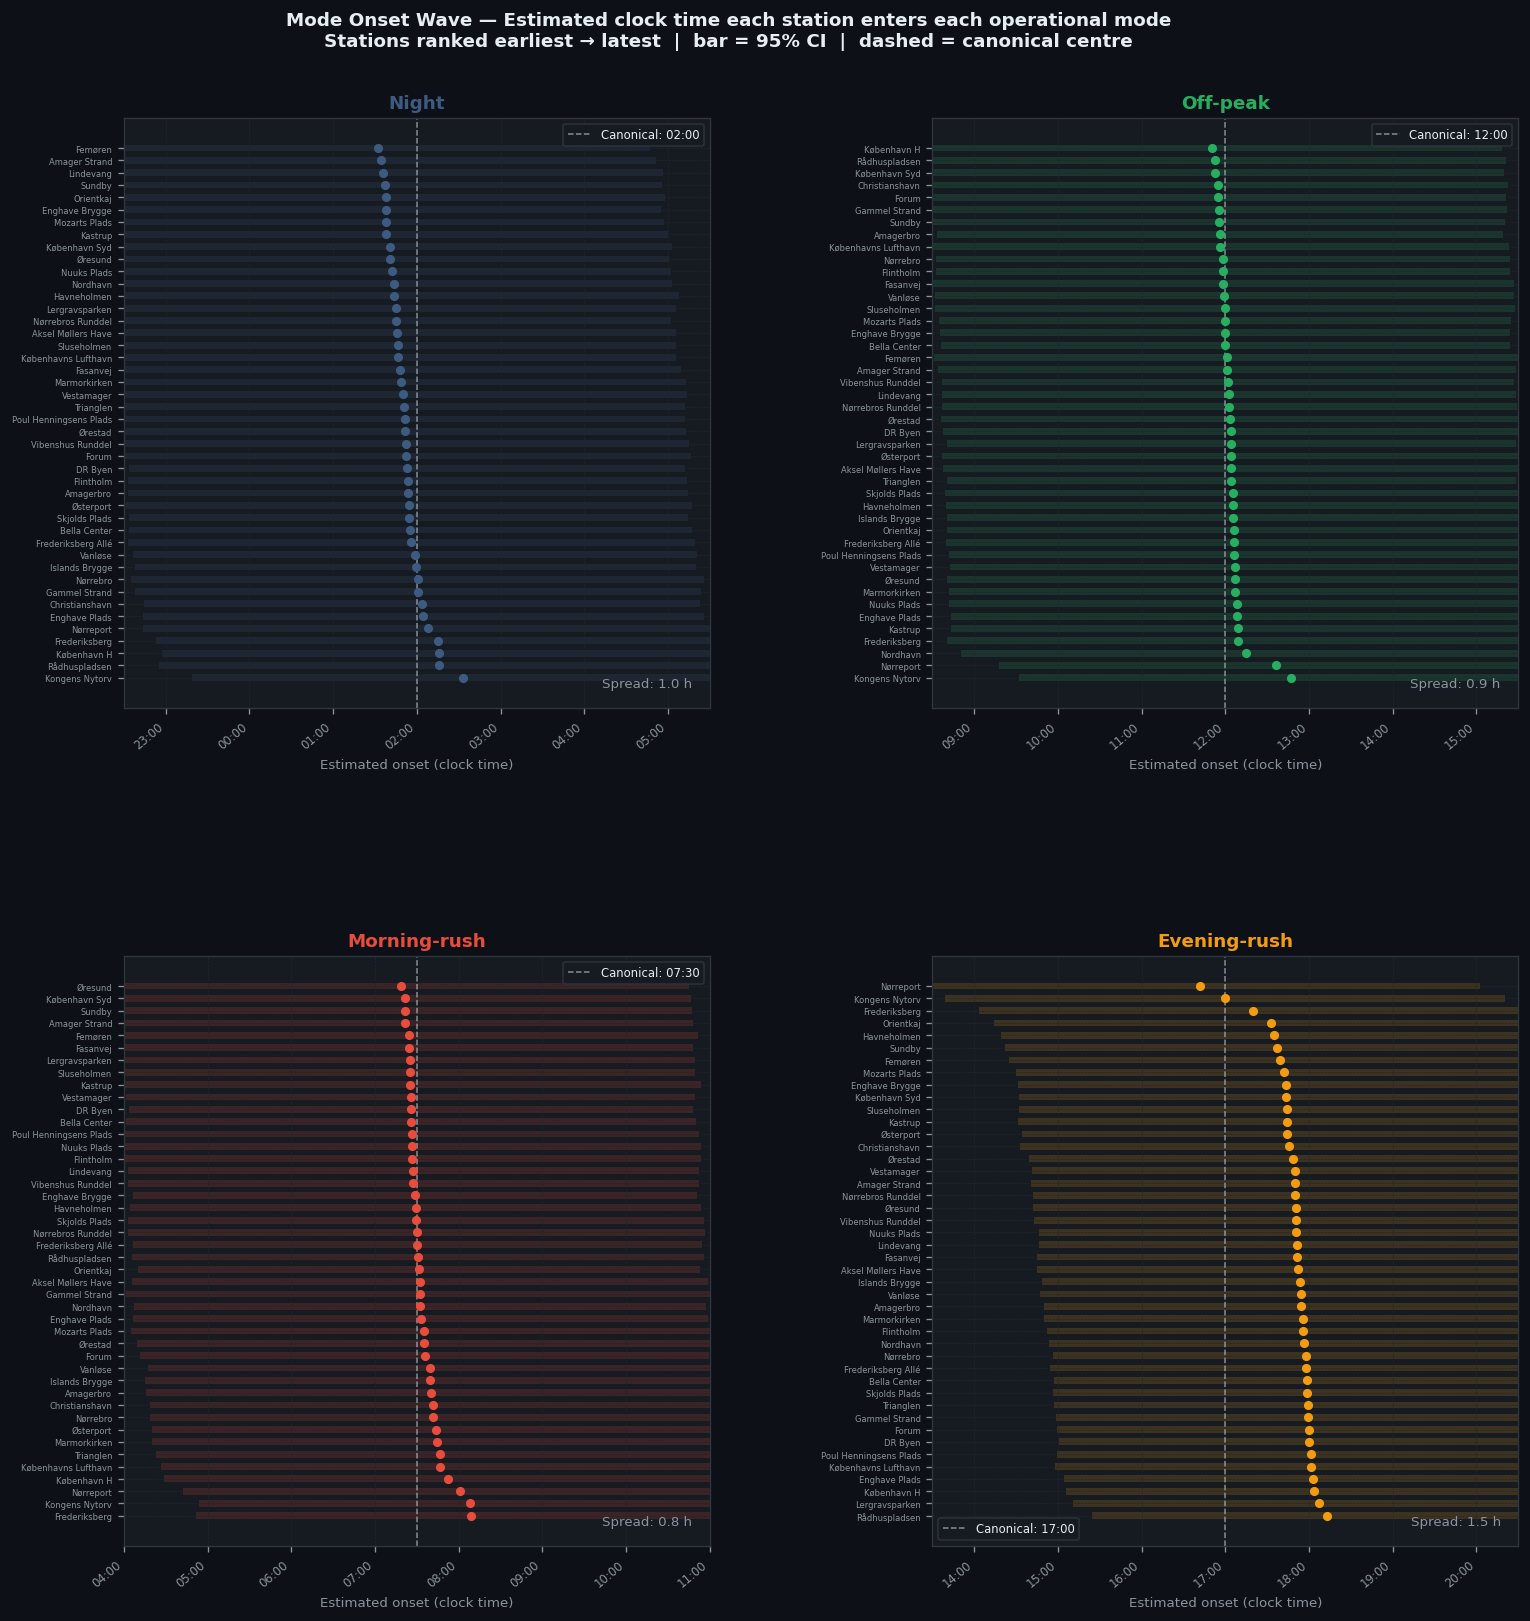

Saved → outputs\plots\metro_mode_onset_wave.png


In [18]:
delay_np = _to_np(station_delay)
dscale_np = _to_np(station_delay_scale)
S_w, K_w = delay_np.shape
onset_abs = MODE_CENTER_HOURS.numpy()[None, :] + delay_np

fig = _fig((14, max(8, 0.22 * S_w + 4)))
fig.suptitle(
    "Mode Onset Wave — Estimated clock time each station enters each operational mode\n"
    "Stations ranked earliest → latest  |  bar = 95% CI  |  dashed = canonical centre",
    color=WHITE, fontsize=11, fontweight="bold", y=0.995,
)
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.42, wspace=0.38,
                       top=0.93, bottom=0.06, left=0.14, right=0.97)

for k, (mode, col) in enumerate(zip(STATE_NAMES, STATE_COLORS_PLOT)):
    ax = fig.add_subplot(gs[k // 2, k % 2]);
    _dark(ax)
    order = np.argsort(onset_abs[:, k])
    onset_r = onset_abs[order, k];
    ci_r = 1.96 * dscale_np[order, k]
    names_r = [station_names[i] for i in order]
    y = np.arange(S_w)
    ax.barh(y, ci_r * 2, left=onset_r - ci_r, height=0.55, color=col, alpha=0.18, zorder=1)
    ax.scatter(onset_r, y, color=col, s=30, zorder=3, linewidths=0)
    center = float(MODE_CENTER_HOURS[k])
    ax.axvline(center, color=WHITE, lw=0.9, ls="--", alpha=0.55, label=f"Canonical: {_hour_label(center)}")
    spread = onset_r.max() - onset_r.min()
    ax.text(0.97, 0.03, f"Spread: {spread:.1f} h", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=8, color=MUTED)
    ax.set_yticks(y);
    ax.set_yticklabels(names_r, fontsize=max(5, 8 - S_w // 10), color=MUTED)
    ax.invert_yaxis()
    pad = MAX_DELAY_HOURS + 0.5
    tick_h = np.arange(np.ceil(center - pad), np.floor(center + pad) + 1)
    ax.set_xlim(center - pad, center + pad)
    ax.set_xticks(tick_h);
    ax.set_xticklabels([_hour_label(h) for h in tick_h], fontsize=7, rotation=40, ha="right")
    ax.set_xlabel("Estimated onset (clock time)", fontsize=8)
    ax.set_title(mode, color=col, fontsize=11, fontweight="bold")
    ax.legend(fontsize=7, labelcolor=WHITE, facecolor=PANEL, edgecolor="#30363d")

out_p = OUT_DIR / "plots" / "metro_mode_onset_wave.png"
plt.savefig(out_p, dpi=150, bbox_inches="tight", facecolor=BG);
plt.show()
print(f"Saved → {out_p}")


## Count rates (passengers/min)

Mean entering and exiting from metro rates per mode, expressed in **passengers per minute** (= λ / 15). Individual station values are shown as jittered dots behind the mean bars.


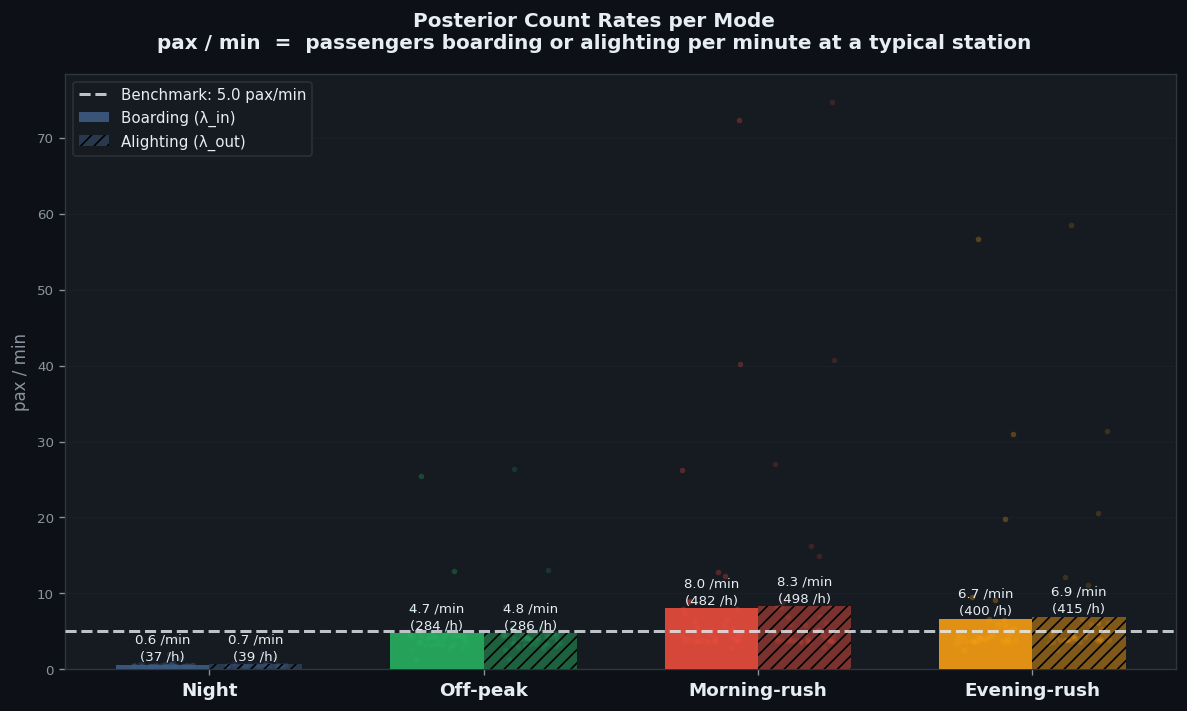

Saved → outputs\plots\metro_count_rates.png


In [19]:
lin = _to_np(lambda_in) / 15.0  # pass/15min → pass/min
lout = _to_np(lambda_out) / 15.0
K_cr, S_cr = lin.shape
mean_in = lin.mean(axis=1);
mean_out = lout.mean(axis=1)
ref_rate = 5.0

fig = _fig((10, 6))
fig.suptitle(
    "Posterior Count Rates per Mode\n"
    "pass / min  =  passengers entering or leaving per minute at a typical station",
    color=WHITE, fontsize=12, fontweight="bold",
)
ax = fig.add_subplot(1, 1, 1);
_dark(ax)
ax.grid(axis="y", color=GRID, linewidth=0.4, linestyle="--", zorder=0)
ax.grid(axis="x", visible=False)
x = np.arange(K_cr);
w = 0.34;
rng = np.random.default_rng(0)
bars_in = ax.bar(x - w / 2, mean_in, w, color=STATE_COLORS_PLOT, alpha=0.92, label="Boarding (λ_in)", zorder=3)
bars_out = ax.bar(x + w / 2, mean_out, w, color=STATE_COLORS_PLOT, alpha=0.48, hatch="///", label="Alighting (λ_out)",
                  zorder=3)
for k in range(K_cr):
    jit = rng.uniform(-0.11, 0.11, S_cr)
    ax.scatter(k - w / 2 + jit, lin[k], s=11, color=STATE_COLORS_PLOT[k], alpha=0.30, linewidths=0, zorder=2)
    ax.scatter(k + w / 2 + jit, lout[k], s=11, color=STATE_COLORS_PLOT[k], alpha=0.18, linewidths=0, zorder=2)
ax.axhline(ref_rate, color=WHITE, lw=1.8, ls="--", alpha=0.80, label=f"Benchmark: {ref_rate} pass/min", zorder=4)
for bar, val in zip(list(bars_in) + list(bars_out), list(mean_in) + list(mean_out)):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.20,
            f"{val:.1f} /min\n({val * 60:.0f} /h)",
            ha="center", va="bottom", fontsize=8, color=WHITE, linespacing=1.4)
ax.set_xticks(x);
ax.set_xticklabels(STATE_NAMES, color=WHITE, fontsize=11, fontweight="bold")
ax.set_ylabel("pass / min", fontsize=10, color=MUTED)
ax.legend(fontsize=9, labelcolor=WHITE, facecolor=PANEL, edgecolor="#30363d", loc="upper left")
plt.tight_layout()
out_p = OUT_DIR / "plots" / "metro_count_rates.png"
plt.savefig(out_p, dpi=150, bbox_inches="tight", facecolor=BG);
plt.show()
print(f"Saved → {out_p}")


### Mode hours lifecycle

Stacked horizontal bars showing how many hours per day each station spends in each mode. Stations are ranked by morning-rush hours (highest at top).


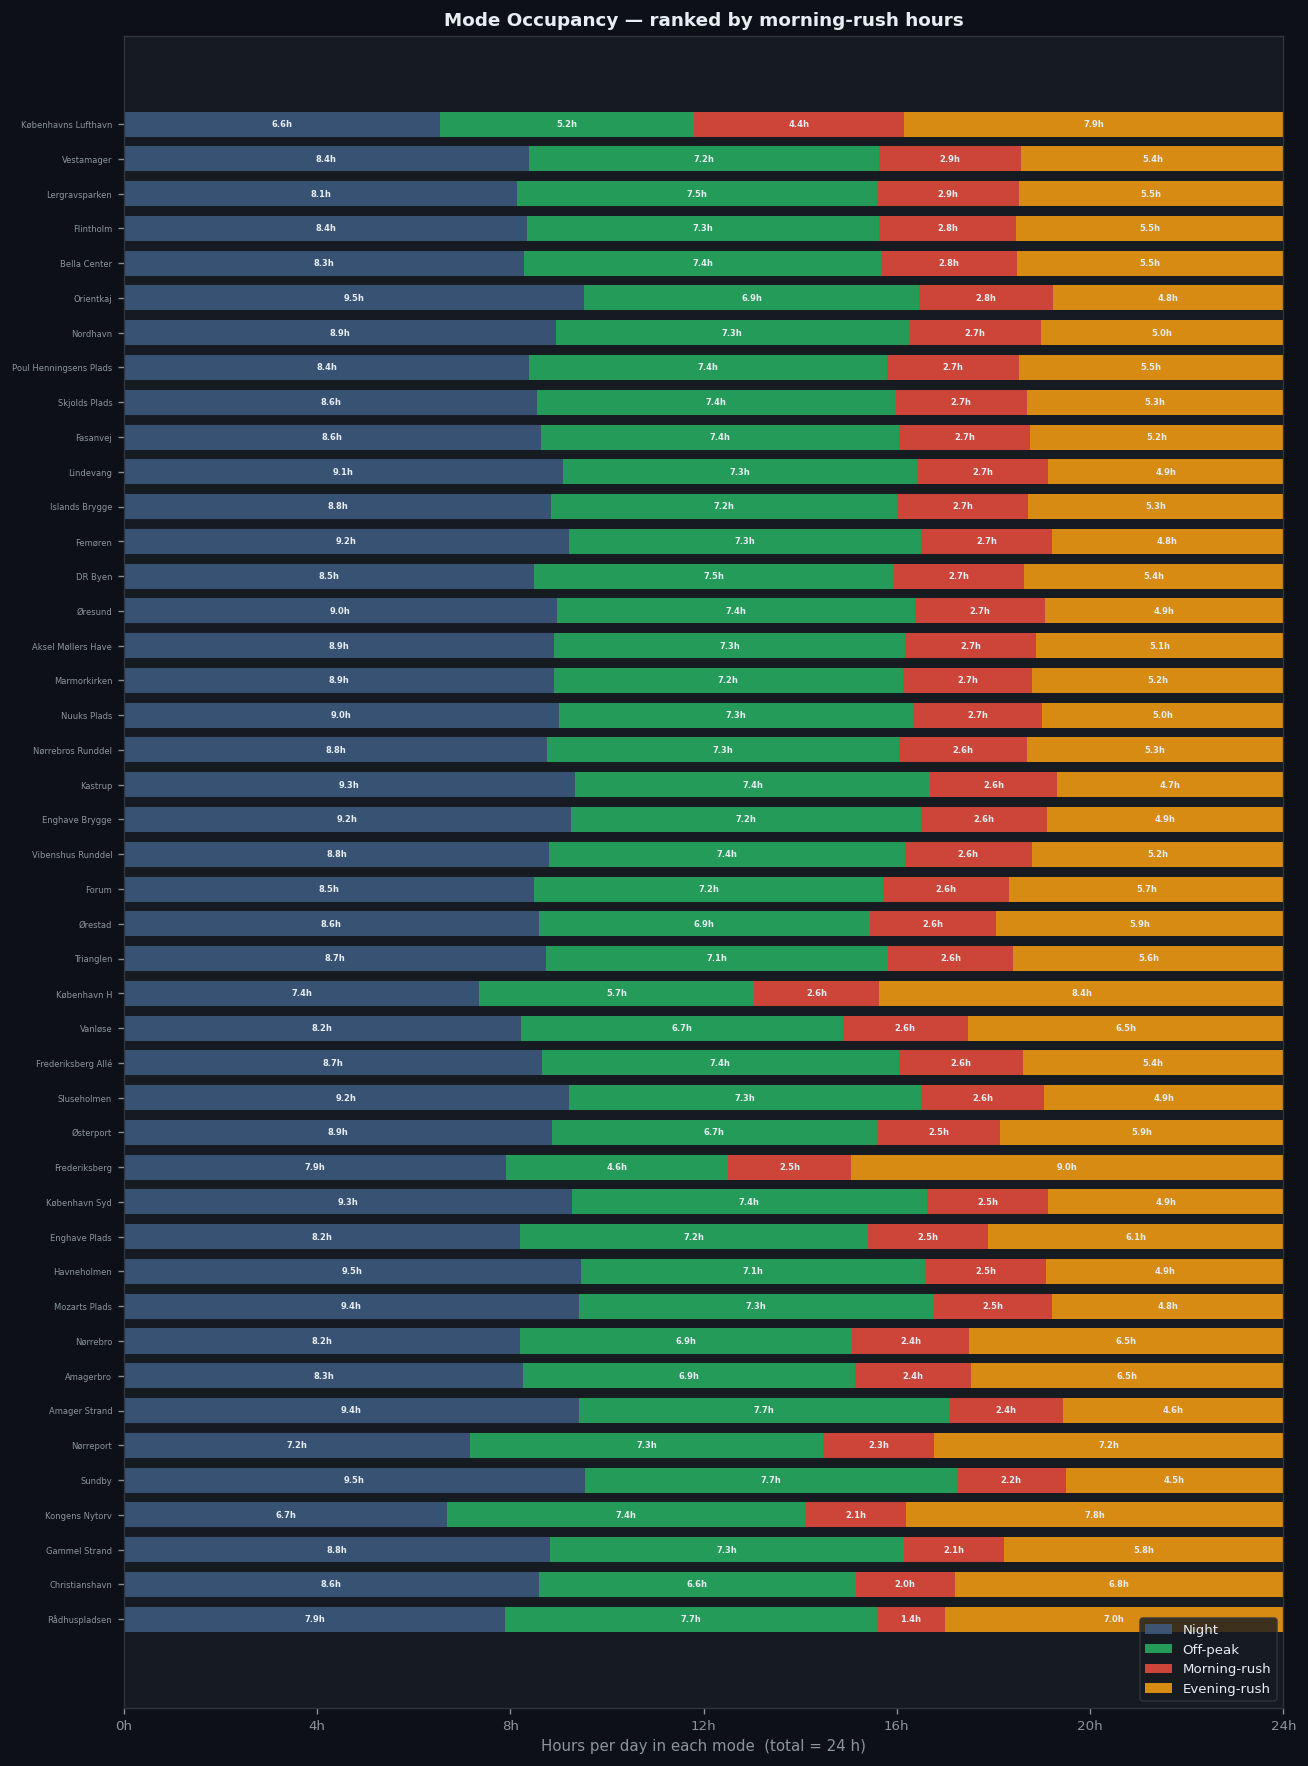

Saved → outputs\plots\metro_mode_occupancy.png


In [20]:
g_occ = _to_np(gamma);
occ = g_occ.mean(axis=1) * 24.0  # [S, K] hours/day
S_oc, K_oc = occ.shape
order = np.argsort(occ[:, STATE_NAMES.index("Morning-rush")])[::-1]
occ_s = occ[order];
names_s = [station_names[i] for i in order]

fig = _fig((11, max(6, 0.28 * S_oc + 2.5)));
ax = fig.add_subplot(1, 1, 1);
_dark(ax);
ax.grid(False)
y_oc = np.arange(S_oc);
left = np.zeros(S_oc)
for k in range(K_oc):
    col = STATE_COLORS_PLOT[k]
    ax.barh(y_oc, occ_s[:, k], left=left, height=0.72, color=col, alpha=0.88, label=STATE_NAMES[k])
    for i in range(S_oc):
        if occ_s[i, k] >= 1.0:
            ax.text(left[i] + occ_s[i, k] / 2, y_oc[i], f"{occ_s[i, k]:.1f}h",
                    ha="center", va="center", fontsize=max(5, 7 - S_oc // 20), color=WHITE, fontweight="bold")
    left += occ_s[:, k]
ax.axvline(24, color=WHITE, lw=0.6, ls=":", alpha=0.20)
ax.set_yticks(y_oc);
ax.set_yticklabels(names_s, fontsize=max(5, 8 - S_oc // 10), color=MUTED)
ax.invert_yaxis();
ax.set_xlim(0, 24)
ax.set_xticks([0, 4, 8, 12, 16, 20, 24])
ax.set_xticklabels(["0h", "4h", "8h", "12h", "16h", "20h", "24h"], fontsize=8, color=MUTED)
ax.set_xlabel("Hours per day in each mode  (total = 24 h)", fontsize=9)
ax.set_title("Mode Occupancy — ranked by morning-rush hours", color=WHITE, fontsize=11, fontweight="bold")
ax.legend(loc="lower right", fontsize=8, labelcolor=WHITE, facecolor=PANEL, edgecolor="#30363d")
plt.tight_layout()
out_p = OUT_DIR / "plots" / "metro_mode_occupancy.png"
plt.savefig(out_p, dpi=150, bbox_inches="tight", facecolor=BG);
plt.show()
print(f"Saved → {out_p}")


### Average daily cycle
System-wide mean P(mode | quarter-hour) across all stations and days.


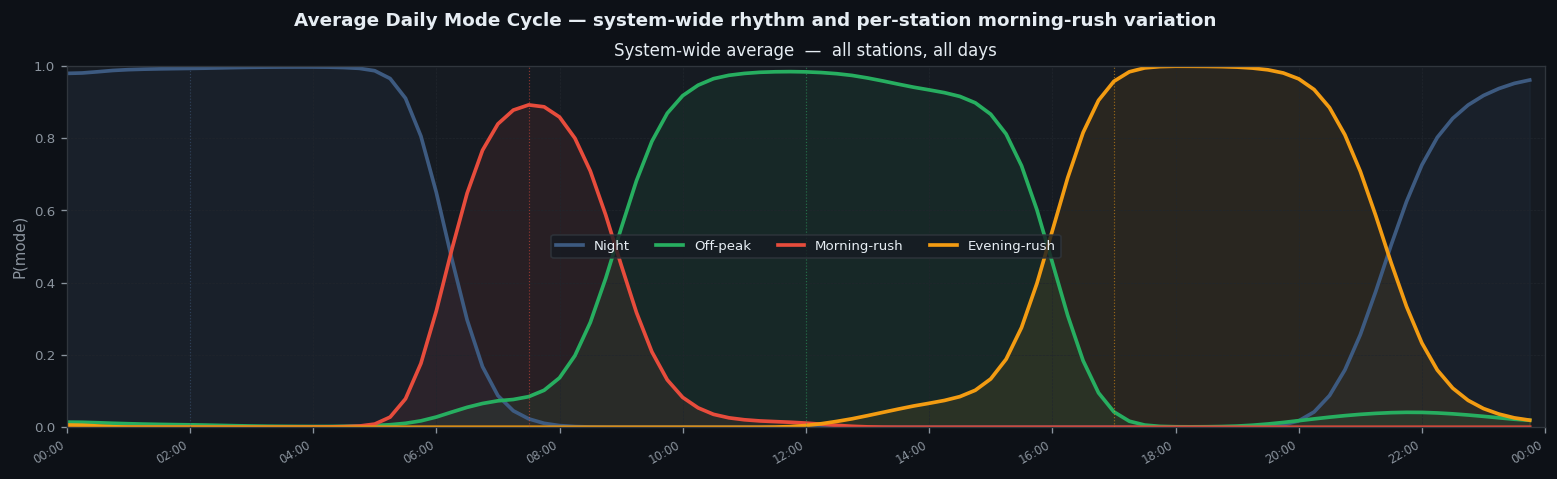

In [38]:
g_day = _daily_gamma(gamma)  # [S, 96, K]
S_dc, _, K_dc = g_day.shape
hours = np.arange(STEPS_PER_DAY) / 4.0
rush_k = STATE_NAMES.index("Morning-rush");
rush_col = STATE_COLORS_PLOT[rush_k]

fig = _fig((14, 9))
fig.suptitle("Average Daily Mode Cycle — system-wide rhythm and per-station morning-rush variation",
             color=WHITE, fontsize=11, fontweight="bold")
gs = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[1, 1.1], hspace=0.42,
                       top=0.93, bottom=0.08, left=0.09, right=0.97)

# System-wide mean
ax0 = fig.add_subplot(gs[0]);
_dark(ax0)
mean_p = g_day.mean(axis=0)
for k in range(K_dc):
    sm = uniform_filter1d(mean_p[:, k], size=4)
    ax0.plot(hours, sm, color=STATE_COLORS_PLOT[k], lw=2.2, label=STATE_NAMES[k])
    ax0.fill_between(hours, 0, sm, color=STATE_COLORS_PLOT[k], alpha=0.09)
for k in range(K_dc):
    ax0.axvline(float(MODE_CENTER_HOURS[k]), color=STATE_COLORS_PLOT[k], lw=0.7, ls=":", alpha=0.55)
ax0.set_xlim(0, 24);
_xticks_hours(ax0, step=2);
ax0.set_ylim(0, 1)
ax0.set_ylabel("P(mode)", fontsize=9)
ax0.set_title("System-wide average  —  all stations, all days", color=WHITE, fontsize=10)
ax0.legend(fontsize=8, labelcolor=WHITE, facecolor=PANEL, edgecolor="#30363d", ncol=4)

### Weekday vs weekend mode cycle

For each mode, the solid line shows the Mon–Fri average and the dashed line shows Sat–Sun. The shaded area highlights the difference.


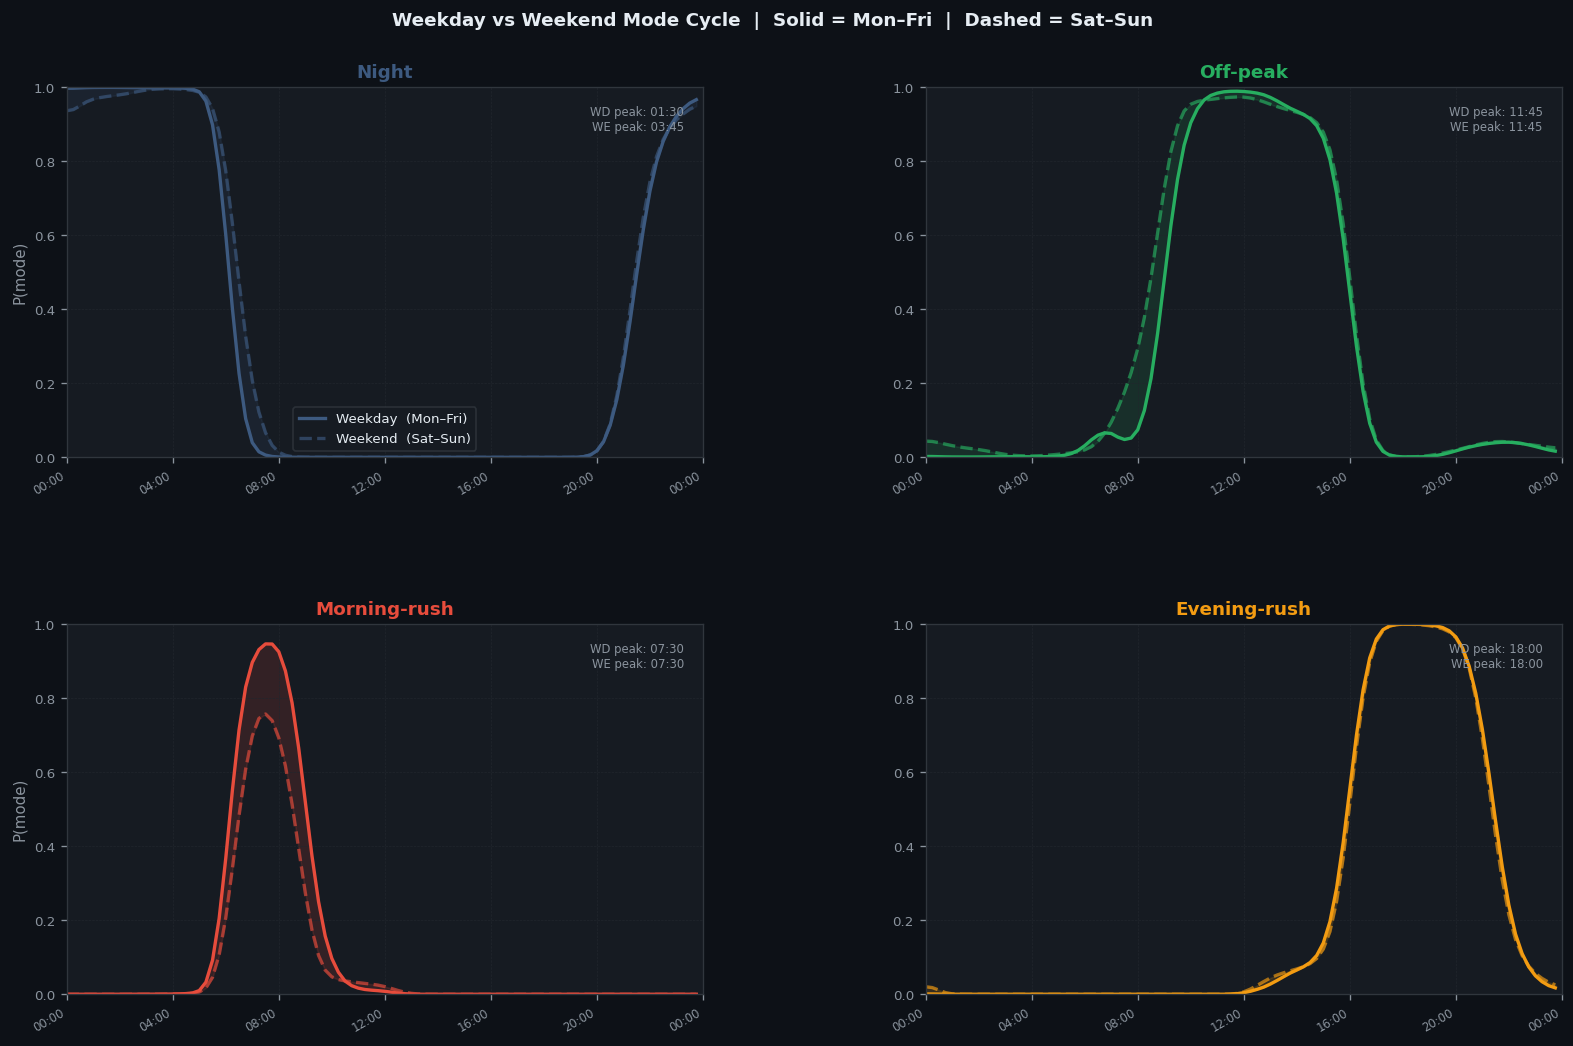

Saved → outputs\plots\metro_weekday_weekend.png


In [22]:
g_ww = _to_np(gamma);
S_ww, T_ww, K_ww = g_ww.shape
ti_ww = time_index[:T_ww];
dow = ti_ww.dayofweek.values;
is_we = (dow >= 5)
qh = (ti_ww.hour * 4 + ti_ww.minute // 15).values
g_mean_s = g_ww.mean(axis=0)
wd_sum = np.zeros((STEPS_PER_DAY, K_ww));
we_sum = np.zeros_like(wd_sum)
wd_cnt = np.zeros(STEPS_PER_DAY);
we_cnt = np.zeros_like(wd_cnt)
for t in range(T_ww):
    q = qh[t]
    if is_we[t]:
        we_sum[q] += g_mean_s[t];
        we_cnt[q] += 1
    else:
        wd_sum[q] += g_mean_s[t];
        wd_cnt[q] += 1
wd_p = wd_sum / np.maximum(wd_cnt, 1)[:, None]
we_p = we_sum / np.maximum(we_cnt, 1)[:, None]
hours_ww = np.arange(STEPS_PER_DAY) / 4.0

fig = _fig((14, 9))
fig.suptitle("Weekday vs Weekend Mode Cycle  |  Solid = Mon–Fri  |  Dashed = Sat–Sun",
             color=WHITE, fontsize=11, fontweight="bold")
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35,
                       top=0.91, bottom=0.07, left=0.08, right=0.97)
for k in range(K_ww):
    ax = fig.add_subplot(gs[k // 2, k % 2]);
    _dark(ax);
    col = STATE_COLORS_PLOT[k]
    wd_sm = uniform_filter1d(wd_p[:, k], size=4);
    we_sm = uniform_filter1d(we_p[:, k], size=4)
    ax.plot(hours_ww, wd_sm, color=col, lw=2.0, label="Weekday  (Mon–Fri)")
    ax.plot(hours_ww, we_sm, color=col, lw=2.0, ls="--", alpha=0.65, label="Weekend  (Sat–Sun)")
    ax.fill_between(hours_ww, wd_sm, we_sm, color=col, alpha=0.14)
    wd_peak = hours_ww[np.argmax(wd_sm)];
    we_peak = hours_ww[np.argmax(we_sm)]
    ax.text(0.97, 0.95, f"WD peak: {_hour_label(wd_peak)}\nWE peak: {_hour_label(we_peak)}",
            transform=ax.transAxes, ha="right", va="top", fontsize=7, color=MUTED)
    ax.set_xlim(0, 24);
    _xticks_hours(ax, step=4);
    ax.set_ylim(0, 1)
    ax.set_ylabel("P(mode)" if k % 2 == 0 else "", fontsize=9)
    ax.set_title(STATE_NAMES[k], color=col, fontsize=11, fontweight="bold")
    if k == 0: ax.legend(fontsize=8, labelcolor=WHITE, facecolor=PANEL, edgecolor="#30363d")
out_p = OUT_DIR / "plots" / "metro_weekday_weekend.png"
plt.savefig(out_p, dpi=150, bbox_inches="tight", facecolor=BG);
plt.show()
print(f"Saved → {out_p}")


### Mode onset clustering
Cluster in each mode the stations based on the timestep they are estimated to enter (green = early, red = late)


In [35]:
try:
    import folium
    import matplotlib.colors as mcolors
    from IPython.display import display, HTML, IFrame  # ← added IFrame
    _has_folium = True
except ImportError:
    print("folium not installed — skipping maps.  Run: pip install folium")
    _has_folium = False

if _has_folium:  # ← everything below is now inside this guard
    delay_csv_path = OUT_DIR / "metro_station_mode_delays.csv"

    coords = (meta[["station", "lat", "lon"]].drop_duplicates("station")
              .dropna(subset=["lat", "lon"]).set_index("station"))
    df_delays = pd.read_csv(delay_csv_path)
    map_center = [coords["lat"].mean(), coords["lon"].mean()]

    def _t2m(t):  # ← moved outside the for loop (no need to redefine each iteration)
        h, m = map(int, str(t).strip().split(":"))
        return h * 60 + m

    for mode in STATE_NAMES:  # ← loop body is now fully indented
        delay_col = f"{mode}_delay_h"
        center_col = f"{mode}_relative_center"  # ← indented into loop

        if delay_col not in df_delays.columns:  # ← indented into loop
            continue

        df_mode = df_delays[["station", delay_col, center_col]].dropna()
        df_mode = df_mode[df_mode["station"].isin(coords.index)].copy()
        if df_mode.empty:
            continue

        df_mode["entry_minutes"] = df_mode[center_col].apply(_t2m)
        df_mode["bin_15"] = df_mode["entry_minutes"] // 15
        df_mode["bin_label"] = df_mode["bin_15"].apply(
            lambda b: f"{(b * 15) // 60:02d}:{(b * 15) % 60:02d}–"
                      f"{((b + 1) * 15) // 60:02d}:{((b + 1) * 15) % 60:02d}")

        unique_bins = sorted(df_mode["bin_15"].unique())
        n_bins = len(unique_bins)
        cmap = plt.cm.RdYlGn_r
        bin_to_color = {b: mcolors.to_hex(cmap(i / max(n_bins - 1, 1)))
                        for i, b in enumerate(unique_bins)}
        df_mode["color"] = df_mode["bin_15"].map(bin_to_color)

        fmap = folium.Map(location=map_center, zoom_start=12, tiles="CartoDB positron")

        legend_rows = "".join(
            f'<div style="display:flex;align-items:center;margin-bottom:3px">'
            f'<span style="display:inline-block;width:13px;height:13px;border-radius:50%;'
            f'background:{bin_to_color[b]};margin-right:7px"></span>'
            f'<span>{df_mode[df_mode["bin_15"] == b]["bin_label"].iloc[0]}</span></div>'
            for b in unique_bins
        )
        fmap.get_root().html.add_child(folium.Element(
            f'<div style="position:fixed;bottom:30px;left:30px;z-index:1000;background:white;'
            f'padding:14px 18px;border-radius:10px;box-shadow:2px 2px 8px rgba(0,0,0,0.25);'
            f'font-family:sans-serif;font-size:12px;max-height:400px;overflow-y:auto;">'
            f'<b>{mode}<br>Entry time (15-min window)</b>'
            f'<div style="margin-top:8px">{legend_rows}</div></div>'
        ))

        for _, row in df_mode.iterrows():
            lat = coords.loc[row["station"], "lat"]
            lon = coords.loc[row["station"], "lon"]
            folium.CircleMarker(
                location=[lat, lon], radius=11, color="white", weight=2,
                fill=True, fill_color=row["color"], fill_opacity=0.9,
                tooltip=folium.Tooltip(
                    f"<b>{row['station']}</b><br>"
                    f"Enters {mode} at ~<b>{row[center_col]}</b><br>"
                    f"Offset: {row[delay_col]:+.2f}h vs average"),
            ).add_to(fmap)

        out_path = OUT_DIR / f"metro_timing_map_{mode.replace('-', '_')}.html"
        fmap.save(str(out_path))
        print(f"Saved → {out_path}")

        display(HTML(
            f"<h3 style='font-family:sans-serif;margin-top:1.5em'>"
            f"{mode} — station entry times "
            f"<span style='font-size:0.8em;color:#666'>({n_bins} distinct 15-min windows, "
            f"green = early, red = late)</span></h3>"
        ))
        b64 = base64.b64encode(out_path.read_bytes()).decode("utf-8")
        display(HTML(
            f'<iframe src="data:text/html;base64,{b64}" '
            f'width="100%" height="500px" frameborder="0"></iframe>'))

Saved → plots\metro_timing_map_Night.html


C:\Users\dimitrioud\AppData\Roaming\Python\Python312\site-packages\IPython\core\display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Saved → plots\metro_timing_map_Off_peak.html


C:\Users\dimitrioud\AppData\Roaming\Python\Python312\site-packages\IPython\core\display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Saved → plots\metro_timing_map_Morning_rush.html


C:\Users\dimitrioud\AppData\Roaming\Python\Python312\site-packages\IPython\core\display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Saved → plots\metro_timing_map_Evening_rush.html


C:\Users\dimitrioud\AppData\Roaming\Python\Python312\site-packages\IPython\core\display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


### Specific date mode detection
Use the slider to see how modes spread over the given day in all stations.

In [26]:
# !pip install folium branca

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import folium
from folium.plugins import TimestampedGeoJson
from IPython.display import display

STATE_NAMES = ["Night", "Off-peak", "Morning-rush", "Evening-rush"]
STATE_COLORS = ["#1a1a2e", "#27ae60", "#e74c3c", "#f39c12"]

OUT_DIR = Path("plots")
OUT_DIR.mkdir(exist_ok=True)

# Convert gamma
gamma_np = gamma.detach().cpu().numpy() if isinstance(gamma, torch.Tensor) else np.asarray(gamma)
time_index = pd.DatetimeIndex(time_index)

coords = (
    meta[["station", "lat", "lon"]]
    .drop_duplicates("station")
    .dropna(subset=["lat", "lon"])
    .set_index("station")
)

# Use one representative day, not whole dataset
# Change this date if you want another day
selected_day = time_index[0].date()

day_mask = time_index.date == selected_day
day_indices = np.where(day_mask)[0]

# Optional: reduce from every 15 min to every 30/60 min
step = 2  # 2 = every 30 min, 4 = every 1 hour
day_indices = day_indices[::step]

features = []

for t_idx in day_indices:
    actual_time = time_index[t_idx]

    for s, station in enumerate(station_names):
        if station not in coords.index:
            continue

        probs = gamma_np[s, t_idx, :]
        state_idx = int(np.argmax(probs))
        state = STATE_NAMES[state_idx]
        color = STATE_COLORS[state_idx]
        confidence = float(probs[state_idx])

        features.append({
            "type": "Feature",
            "geometry": {
                "type": "Point",
                "coordinates": [
                    float(coords.loc[station, "lon"]),
                    float(coords.loc[station, "lat"])
                ],
            },
            "properties": {
                "time": actual_time.isoformat(),
                "style": {
                    "color": "white",
                    "fillColor": color,
                    "fillOpacity": 0.9,
                    "weight": 2,
                    "radius": 5 + 8 * confidence,
                },
                "icon": "circle",
                "popup": (
                    f"<b>{station}</b><br>"
                    f"Time: {actual_time}<br>"
                    f"State: <b>{state}</b><br>"
                    f"Confidence: {confidence:.2f}<br><br>"
                    f"P(Night): {probs[0]:.2f}<br>"
                    f"P(Off-peak): {probs[1]:.2f}<br>"
                    f"P(Morning-rush): {probs[2]:.2f}<br>"
                    f"P(Evening-rush): {probs[3]:.2f}"
                ),
            },
        })

geojson = {
    "type": "FeatureCollection",
    "features": features,
}

map_center = [
    coords["lat"].mean(),
    coords["lon"].mean()
]

fmap = folium.Map(
    location=map_center,
    zoom_start=12,
    tiles="CartoDB positron"
)

TimestampedGeoJson(
    geojson,
    period="PT30M",  # 30-minute slider step
    duration="PT30M",
    transition_time=500,
    auto_play=False,
    loop=False,
    max_speed=5,
    loop_button=True,
    date_options="YYYY-MM-DD HH:mm",
    time_slider_drag_update=True,
).add_to(fmap)

legend_html = """
<div style="
    position: fixed;
    top: 30px;
    right: 30px;
    z-index: 9999;
    background: white;
    padding: 14px 18px;
    border-radius: 10px;
    box-shadow: 2px 2px 8px rgba(0,0,0,0.25);
    font-family: Arial, sans-serif;
    font-size: 13px;
">
<b>Metro hidden state</b><br><br>
"""

for state, color in zip(STATE_NAMES, STATE_COLORS):
    legend_html += f"""
    <div style="display:flex; align-items:center; margin-bottom:5px;">
        <span style="
            display:inline-block;
            width:14px;
            height:14px;
            border-radius:50%;
            background:{color};
            margin-right:8px;">
        </span>
        <span>{state}</span>
    </div>
    """

legend_html += """
<div style="font-size:11px; margin-top:8px; color:#555;">
Use the slider to see how modes spread over the day.
</div>
</div>
"""

fmap.get_root().html.add_child(folium.Element(legend_html))
out_path = OUT_DIR / f"metro_selected_{selected_day}_mode_map.html"
fmap.save(str(out_path))
print(f"Showing day: {selected_day}")
print(f"Saved → {out_path}")

b64 = base64.b64encode(out_path.read_bytes()).decode("utf-8")
display(HTML(
    f'<iframe src="data:text/html;base64,{b64}" '
    f'width="100%" height="550px" frameborder="0"></iframe>'
))

Showing day: 2024-04-01
Saved → plots\metro_selected_2024-04-01_mode_map.html


C:\Users\dimitrioud\AppData\Roaming\Python\Python312\site-packages\IPython\core\display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## Demand Volatility Matrix

This scatter plot positions every station in a **baseline load × peak spike** space, revealing four operationally distinct station types.

### What the axes measure

- **X-axis — off-peak rate** (passengers / 15 min): how busy a station is during a *normal*, non-rush period. A high value means the station carries heavy load even outside rush hours.
- **Y-axis — Demand Volatility Index (DVI)**: the ratio of worst-case peak flow to off-peak baseline.

$$\text{DVI}[s] = \frac{\max(\lambda^{\text{in}}_{\text{rush}}[s],\ \lambda^{\text{out}}_{\text{rush}}[s])}{\lambda^{\text{in}}_{\text{off-peak}}[s]}$$

A DVI of 3 means the station is **3× busier during rush hour** than during a typical off-peak slot.

| Quadrant | OFR  | DVI  | Operational implication |
|---|------|------|---|
| 🔴 Top-right | High | High | Hardest to manage — always busy *and* spikes sharply |
| 🟠 Bottom-right | High | Low  | Baseline capacity is the constraint; staffing is predictable |
| 🟣 Top-left | Low  | High | Spike risk — elastic staffing and flexible gate deployment needed |
| 🟢 Bottom-left | Low  | Low  | Easiest to plan; stable and low-demand throughout the day |

The dashed lines are system medians — stations above/right of them are above average on that dimension.
A station with high  off-peak rate but low DVI needs permanent infrastructure investment. A station with low baseline but high DVI needs *elastic* resources that can be deployed quickly and withdrawn outside rush hours. These require completely different operational responses, and this plot makes that distinction immediately visible.

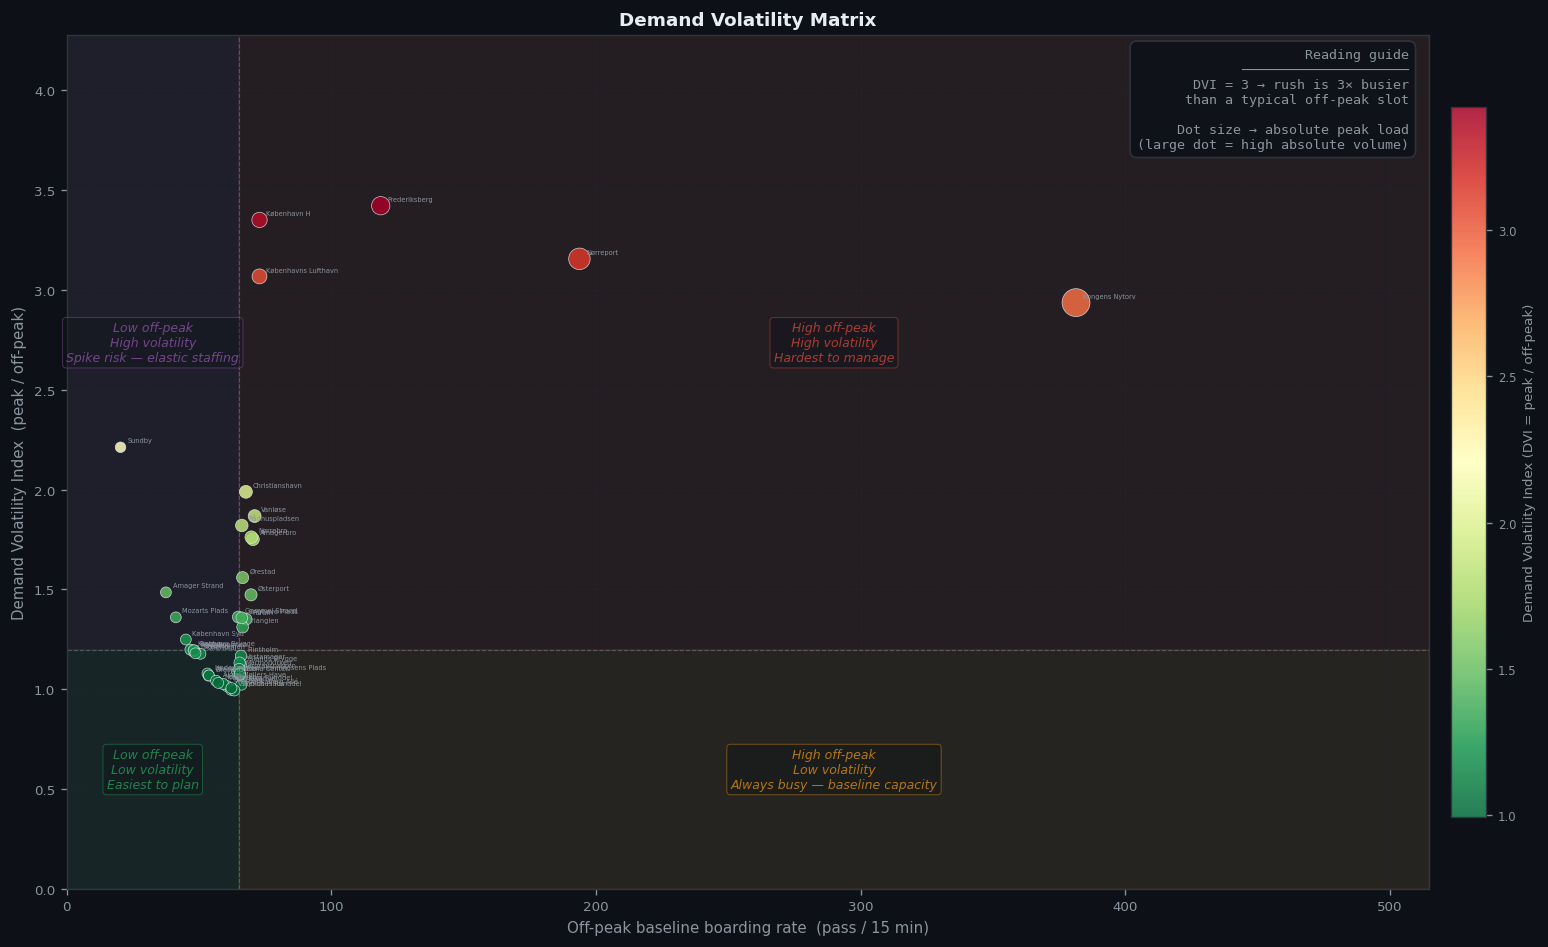

In [40]:
def _colorbar(im, ax: plt.Axes, label: str = "") -> None:
    cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.015)
    cbar.ax.tick_params(colors=MUTED, labelsize=7)
    cbar.set_label(label, color=MUTED, fontsize=8)
    cbar.outline.set_edgecolor("#30363d")


"""
Demand Volatility Index per station:

    DVI[s] = max(λ_rush_in[s], λ_rush_out[s]) / λ_offpeak_in[s]

Answers: "how much does passenger flow spike relative to a normal period?"

High DVI  → demand multiplies sharply during rush; needs elastic staffing,
            flexible gate deployment, dynamic train frequency.
Low DVI   → stable load throughout the day; easier to plan but may signal
            an always-busy station where baseline capacity is the constraint.

Scatter plot: x = off-peak baseline rate, y = DVI.
Quadrants reveal four operationally distinct station types.
"""
lin = _to_np(lambda_in)  # [K, S]
lout = _to_np(lambda_out)  # [K, S]
K, S = lin.shape

offpeak_k = STATE_NAMES.index("Off-peak")
rush_k = STATE_NAMES.index("Morning-rush")
eve_k = STATE_NAMES.index("Evening-rush")

base = lin[offpeak_k].clip(0.1)  # [S] pass/15-min at off-peak
peak_rush = np.maximum(lin[rush_k], lout[rush_k])
peak_eve = np.maximum(lin[eve_k], lout[eve_k])
peak = np.maximum(peak_rush, peak_eve)  # [S] worst-case peak

dvi = peak / base  # [S] ratio

# Quadrant thresholds: median split on both axes
base_med = np.median(base)
dvi_med = np.median(dvi)

quadrant_labels = {
    (True, True): ("High off-peak\nHigh volatility", "#e74c3c", "Hardest to manage"),
    (True, False): ("High off-peak\nLow volatility", "#f39c12", "Always busy — baseline capacity"),
    (False, True): ("Low off-peak\nHigh volatility", "#9b59b6", "Spike risk — elastic staffing"),
    (False, False): ("Low off-peak\nLow volatility", "#27ae60", "Easiest to plan"),
}

fig = _fig((13, 8))
ax = fig.add_subplot(1, 1, 1)
_dark(ax)

# Quadrant shading
xmax = base.max() * 1.35
ymax = dvi.max() * 1.25
ax.axhline(dvi_med, color=MUTED, lw=0.7, ls="--", alpha=0.45)
ax.axvline(base_med, color=MUTED, lw=0.7, ls="--", alpha=0.45)

quad_fills = [
    (base_med, xmax, dvi_med, ymax, "#e74c3c", 0.07),
    (base_med, xmax, 0, dvi_med, "#f39c12", 0.07),
    (0, base_med, dvi_med, ymax, "#9b59b6", 0.07),
    (0, base_med, 0, dvi_med, "#27ae60", 0.07),
]
for x0, x1, y0, y1, col, alpha in quad_fills:
    ax.fill_betweenx([y0, y1], x0, x1, color=col, alpha=alpha, zorder=0)

# Quadrant corner labels
offset_x = xmax * 0.01
offset_y = ymax * 0.01
for (high_base, high_dvi), (qlabel, qcol, qhint) in quadrant_labels.items():
    cx = (base_med + xmax) / 2 if high_base else base_med * 0.5
    cy = (dvi_med + ymax) / 2 if high_dvi else dvi_med * 0.5
    ax.text(cx, cy, f"{qlabel}\n{qhint}",
            ha="center", va="center", fontsize=7.5,
            color=qcol, alpha=0.70, style="italic",
            bbox=dict(boxstyle="round,pad=0.3", facecolor=BG,
                      edgecolor=qcol, alpha=0.40, linewidth=0.6))

# Scatter — size encodes peak absolute volume
sizes = (peak / peak.max()) * 250 + 30
sc = ax.scatter(base, dvi, s=sizes, c=dvi, cmap="RdYlGn_r",
                vmin=dvi.min(), vmax=dvi.max(),
                alpha=0.85, zorder=4, linewidths=0.4,
                edgecolors=WHITE)

# Label every station
for s in range(S):
    ax.annotate(
        station_names[s],
        (base[s], dvi[s]),
        xytext=(4, 3), textcoords="offset points",
        fontsize=max(4, 6 - S // 15), color=MUTED, zorder=5,
    )
_colorbar(sc, ax, label="Demand Volatility Index (DVI = peak / off-peak)")

ax.set_xlim(0, xmax)
ax.set_ylim(0, ymax)
ax.set_xlabel("Off-peak baseline boarding rate  (pass / 15 min)", fontsize=9)
ax.set_ylabel("Demand Volatility Index  (peak / off-peak)", fontsize=9)
ax.set_title(
    "Demand Volatility Matrix",
    color=WHITE, fontsize=11, fontweight="bold",
)

# Reading guide
ax.text(
    0.985, 0.985,
    "Reading guide\n"
    "─────────────────────\n"
    "DVI = 3 → rush is 3× busier\n"
    "than a typical off-peak slot\n\n"
    "Dot size → absolute peak load\n"
    "(large dot = high absolute volume)",
    transform=ax.transAxes, ha="right", va="top",
    fontsize=8, color=MUTED, family="monospace",
    bbox=dict(boxstyle="round,pad=0.5", facecolor=BG,
              edgecolor="#30363d", alpha=0.90),
)

plt.tight_layout()

### HMM anomaly detection
Computes a signed residual at every (station, timestep):
signed_residual[s, t] = (observed_total[s,t] − expected_total[s,t])  / sqrt(expected_total[s,t] + ε)

where expected_total is the HMM posterior-weighted Poisson mean: expected_total[s,t] = Σ_k γ[s,t,k] * (λ_in[k,s] + λ_out[k,s])

 Rule-based group assignment (no ML clustering):
   direction = surge  if mean(positive residual) > 1.2 × mean(negative)
             = drop   if mean(negative residual) > 1.2 × mean(positive)
             = mixed  otherwise
   severity  = high / medium / low based on mean_abs_residual quantiles

 Map: circle colour = group, radius ∝ mean anomaly strength.
 Click a station for full breakdown by mode

In [25]:
# !pip install folium branca

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import folium
from IPython.display import display

# ==================================================
# CONFIG
# ==================================================

OUT_DIR = Path("plots")
OUT_DIR.mkdir(exist_ok=True)

STATE_NAMES = ["Night", "Off-peak", "Morning-rush", "Evening-rush"]

GROUP_COLORS = {
    "Severe overcrowding risk": "#c0392b",
    "Elevated passenger demand": "#e67e22",
    "Mild demand increase": "#f6b93b",

    "Severe underutilization": "#8e44ad",
    "Reduced passenger activity": "#3498db",
    "Slightly below expected demand": "#74b9ff",

    "Unstable passenger dynamics": "#f1c40f",

    "Expected operational behavior": "#2ecc71",
}

threshold = 3.0

# ==================================================
# CONVERT INPUTS
# ==================================================

gamma_np = gamma.detach().cpu().numpy() if isinstance(gamma, torch.Tensor) else np.asarray(gamma)
lambda_in_np = lambda_in.detach().cpu().numpy() if isinstance(lambda_in, torch.Tensor) else np.asarray(lambda_in)
lambda_out_np = lambda_out.detach().cpu().numpy() if isinstance(lambda_out, torch.Tensor) else np.asarray(lambda_out)

ins_np = ins.detach().cpu().numpy() if isinstance(ins, torch.Tensor) else np.asarray(ins)
outs_np = outs.detach().cpu().numpy() if isinstance(outs, torch.Tensor) else np.asarray(outs)

time_index = pd.DatetimeIndex(time_index)

# ==================================================
# HMM EXPECTED VS OBSERVED FLOW
# ==================================================

expected_in = np.einsum("stk,ks->st", gamma_np, lambda_in_np)
expected_out = np.einsum("stk,ks->st", gamma_np, lambda_out_np)
expected_total = expected_in + expected_out

observed_total = ins_np + outs_np

# Important fix: if ins/outs are scaled but lambda is real, rescale observed counts
if "obs_scale" in globals():
    if observed_total.mean() < expected_total.mean() * 0.25:
        # print("Detected scaled observed counts. Rescaling observed_total using obs_scale.")
        observed_total = observed_total * obs_scale

eps = 1e-6
signed_residual = (observed_total - expected_total) / np.sqrt(expected_total + eps)
abs_residual = np.abs(signed_residual)

# ==================================================
# RULE-BASED HMM GROUPS
# ==================================================

rows = []

for s, station in enumerate(station_names):
    r = signed_residual[s]
    ar = abs_residual[s]
    g = gamma_np[s]
    hard_states = g.argmax(axis=1)

    mean_abs = float(ar.mean())
    max_abs = float(ar.max())
    anomaly_rate = float((ar > threshold).mean())

    positive_residual = float(np.maximum(r, 0).mean())
    negative_residual = float(np.maximum(-r, 0).mean())

    night_rate = float(((ar > threshold) & (hard_states == 0)).mean())
    offpeak_rate = float(((ar > threshold) & (hard_states == 1)).mean())
    morning_rate = float(((ar > threshold) & (hard_states == 2)).mean())
    evening_rate = float(((ar > threshold) & (hard_states == 3)).mean())

    mode_rates = {
        "Night": night_rate,
        "Off-peak": offpeak_rate,
        "Morning-rush": morning_rate,
        "Evening-rush": evening_rate,
    }

    dominant_mode = max(mode_rates, key=mode_rates.get)

    if positive_residual > negative_residual * 1.2:
        direction = "Demand surge"
    elif negative_residual > positive_residual * 1.2:
        direction = "Demand drop"
    else:
        direction = "Mixed deviation"

    rows.append({
        "station": station,
        "mean_abs_residual": mean_abs,
        "max_abs_residual": max_abs,
        "anomaly_rate": anomaly_rate,
        "mean_positive_residual": positive_residual,
        "mean_negative_residual": negative_residual,
        "direction": direction,
        "dominant_anomaly_mode": dominant_mode,
        "night_anomaly_rate": night_rate,
        "offpeak_anomaly_rate": offpeak_rate,
        "morning_anomaly_rate": morning_rate,
        "evening_anomaly_rate": evening_rate,
        "avg_p_night": float(g[:, 0].mean()),
        "avg_p_offpeak": float(g[:, 1].mean()),
        "avg_p_morning": float(g[:, 2].mean()),
        "avg_p_evening": float(g[:, 3].mean()),
    })

df_hmm_groups = pd.DataFrame(rows)

# Severity based on HMM residual distribution
q_low = df_hmm_groups["mean_abs_residual"].quantile(0.33)
q_high = df_hmm_groups["mean_abs_residual"].quantile(0.66)

def assign_group(row):

    if row["anomaly_rate"] < 0.05:
        return "Expected operational behavior"

    if row["mean_abs_residual"] >= q_high:
        severity = "High"
    elif row["mean_abs_residual"] >= q_low:
        severity = "Medium"
    else:
        severity = "Low"

    direction = row["direction"]

    if direction == "Demand surge":
        if severity == "High":
            return "Severe overcrowding risk"
        elif severity == "Medium":
            return "Elevated passenger demand"
        else:
            return "Mild demand increase"

    elif direction == "Demand drop":
        if severity == "High":
            return "Severe underutilization"
        elif severity == "Medium":
            return "Reduced passenger activity"
        else:
            return "Slightly below expected demand"

    return "Unstable passenger dynamics"

df_hmm_groups["group"] = df_hmm_groups.apply(assign_group, axis=1)
#
# display(df_hmm_groups["group"].value_counts())
# display(df_hmm_groups.sort_values("mean_abs_residual", ascending=False))

# ==================================================
# MAP PLOT
# ==================================================

coords = (
    meta[["station", "lat", "lon"]]
    .drop_duplicates("station")
    .dropna(subset=["lat", "lon"])
    .set_index("station")
)

df_map = df_hmm_groups[df_hmm_groups["station"].isin(coords.index)].copy()
df_map["lat"] = df_map["station"].map(coords["lat"])
df_map["lon"] = df_map["station"].map(coords["lon"])

map_center = [
    df_map["lat"].mean(),
    df_map["lon"].mean()
]

fmap = folium.Map(
    location=map_center,
    zoom_start=12,
    tiles="CartoDB positron"
)

for _, row in df_map.iterrows():
    color = GROUP_COLORS.get(row["group"], "#636e72")

    radius = 6 + min(row["mean_abs_residual"] * 1.2, 14)

    popup_html = f"""
    <b>{row['station']}</b><br>
    HMM anomaly group: <b>{row['group']}</b><br><br>

    Mean anomaly score: <b>{row['mean_abs_residual']:.2f}</b><br>
    Max anomaly score: <b>{row['max_abs_residual']:.2f}</b><br>
    Anomaly rate: <b>{100 * row['anomaly_rate']:.1f}%</b><br><br>

    Direction: <b>{row['direction']}</b><br>
    Dominant anomaly mode: <b>{row['dominant_anomaly_mode']}</b><br><br>

    Positive residual: {row['mean_positive_residual']:.2f}<br>
    Negative residual: {row['mean_negative_residual']:.2f}<br><br>

    Night anomaly rate: {100 * row['night_anomaly_rate']:.1f}%<br>
    Off-peak anomaly rate: {100 * row['offpeak_anomaly_rate']:.1f}%<br>
    Morning-rush anomaly rate: {100 * row['morning_anomaly_rate']:.1f}%<br>
    Evening-rush anomaly rate: {100 * row['evening_anomaly_rate']:.1f}%<br><br>

    Avg P(Night): {row['avg_p_night']:.2f}<br>
    Avg P(Off-peak): {row['avg_p_offpeak']:.2f}<br>
    Avg P(Morning-rush): {row['avg_p_morning']:.2f}<br>
    Avg P(Evening-rush): {row['avg_p_evening']:.2f}
    """

    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=radius,
        color="white",
        weight=2,
        fill=True,
        fill_color=color,
        fill_opacity=0.9,
        popup=folium.Popup(popup_html, max_width=390),
        tooltip=f"{row['station']} — {row['group']}",
    ).add_to(fmap)

# ==================================================
# LEGEND
# ==================================================

legend_html = """
<div style="
    position: fixed;
    top: 30px;
    right: 30px;
    z-index: 9999;
    background: white;
    padding: 14px 18px;
    border-radius: 10px;
    box-shadow: 2px 2px 8px rgba(0,0,0,0.25);
    font-family: Arial, sans-serif;
    font-size: 12px;
    max-width: 390px;
">
<b>HMM anomaly groups</b><br>
<span style="font-size:11px; color:#555;">
Color = rule-based HMM anomaly group<br>
Size = mean anomaly strength
</span>
<hr style="margin:8px 0;">
"""

for group, color in GROUP_COLORS.items():
    count = int((df_map["group"] == group).sum())
    if count == 0:
        continue

    legend_html += f"""
    <div style="display:flex; align-items:flex-start; margin-bottom:7px;">
        <span style="
            display:inline-block;
            width:14px;
            height:14px;
            border-radius:50%;
            background:{color};
            margin-right:8px;
            margin-top:2px;
            flex-shrink:0;">
        </span>
        <span><b>{group}</b><br>
        <span style="font-size:11px;color:#555;">{count} stations</span></span>
    </div>
    """

legend_html += f"""
<hr style="margin:8px 0;">

<div style="font-size:11px; color:#555; line-height:1.45;">
</div>
</div>
"""

fmap.get_root().html.add_child(folium.Element(legend_html))

out_path = OUT_DIR / "metro_hmm_rule_based_anomaly_map.html"
fmap.save(str(out_path))
print(f"Saved map to: {out_path}")

b64 = base64.b64encode(out_path.read_bytes()).decode("utf-8")
display(HTML(
    f'<iframe src="data:text/html;base64,{b64}" '
    f'width="100%" height="600px" frameborder="0"></iframe>'
))

Saved map to: plots\metro_hmm_rule_based_anomaly_map.html


C:\Users\dimitrioud\AppData\Roaming\Python\Python312\site-packages\IPython\core\display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")
